# Trabajo final: Sistema Intelligence de grado de producción
Asistente de una tienda de tecnología que integra RAG (búsqueda híbrida sobre políticas), un Supervisor con tres agentes especialistas, una API FastAPI con validación Pydantic, persistencia en Redis y trazas en Arize Phoenix.


## 1. Instalación de librerías

In [1]:
!pip install -q fastapi uvicorn httpx redis langgraph langgraph-checkpoint-redis langchain-core langchain-community langchain-classic langchain-google-genai langchain-chroma langchain-huggingface langchain-text-splitters chromadb sentence-transformers rank_bm25 tiktoken arize-phoenix arize-phoenix-otel openinference-instrumentation-langchain python-dotenv pytest pytest-asyncio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.63.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
ibis-framework 9.5.0 requires sqlglot<25.21,>=23.4, but you have sqlglot 30.21.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.


## 2. Redis 8 (estado de los trabajos y checkpoints de LangGraph)

In [2]:
%%bash
CODENAME=$(. /etc/os-release && echo $VERSION_CODENAME)
curl -fsSL https://packages.redis.io/gpg | gpg --dearmor --yes -o /usr/share/keyrings/redis-archive-keyring.gpg
echo "deb [signed-by=/usr/share/keyrings/redis-archive-keyring.gpg] https://packages.redis.io/deb $CODENAME main" > /etc/apt/sources.list.d/redis.list
apt-get update -qq > /dev/null 2>&1
apt-get install -y -qq redis > /dev/null 2>&1

MODULOS=$(find / \( -name "redisearch.so" -o -name "rejson.so" \) 2>/dev/null)
ARGS=""
for m in $MODULOS; do ARGS="$ARGS --loadmodule $m"; done
setsid redis-server --daemonize yes $ARGS
sleep 3

redis-server --version
redis-cli ping
redis-cli MODULE LIST | grep -iE "^search$|^ReJSON$"

Redis server v=8.12.0 sha=00000000:1 malloc=jemalloc-5.3.0 bits=64 build=bd898f7a56dfe3d2
PONG
ReJSON
search


## 3. Arize Phoenix (observabilidad)

In [3]:
import subprocess
import time

import httpx
from google.colab import output

subprocess.Popen("setsid nohup phoenix serve > phoenix.log 2>&1 &", shell=True)
time.sleep(15)

try:
    print("Phoenix responde ->", httpx.get("http://localhost:6006", timeout=10).status_code)
except Exception as e:
    print("Phoenix NO responde:", type(e).__name__)

output.serve_kernel_port_as_window(6006, anchor_text="Abrir Phoenix")

Phoenix NO responde: ConnectError
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## 4. Qué modelos de Gemini responden hoy
Los modelos cambian seguido (algunos se dan de baja, otros se saturan), así que se eligen antes de configurar.

In [4]:
import asyncio
import os

from google import genai
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI

os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")

cliente = genai.Client()
candidatos = [m.name.replace("models/", "") for m in list(cliente.models.list())
              if "flash" in m.name and not any(x in m.name for x in ("image", "tts", "audio", "live", "omni"))]

for nombre in candidatos:
    inicio = time.time()
    try:
        prueba = ChatGoogleGenerativeAI(model=nombre, temperature=0, max_retries=0)
        await asyncio.wait_for(prueba.ainvoke("Respondé solo: hola"), timeout=30)
        print(f"OK       {nombre}: {time.time() - inicio:.0f}s")
    except asyncio.TimeoutError:
        print(f"TIMEOUT  {nombre}")
    except Exception as e:
        print(f"ERROR    {nombre}: {str(e)[:90]}")

ERROR    gemini-2.5-flash: Error calling model 'gemini-2.5-flash' (NOT_FOUND): 404 NOT_FOUND. {'error': {'code': 404,
ERROR    gemini-2.5-flash-lite: Error calling model 'gemini-2.5-flash-lite' (NOT_FOUND): 404 NOT_FOUND. {'error': {'code':
ERROR    gemini-3.1-flash-lite: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing 
TIMEOUT  gemini-3.5-flash


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/google/genai/_common.py:875: RuntimeWarning: coroutine 'ClientResponse.json' was never awaited
  def is_duck_type_of(obj: Any, cls: type[pydantic.BaseModel]) -> bool:


OK       gemini-3.5-flash-lite: 1s


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


TIMEOUT  gemini-3.6-flash
ERROR    gemini-3.7-flash: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing 
ERROR    gemini-3.8-flash: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing 


## 5. Variables de entorno (.env, no se sube al repo)

In [6]:
import os
from google.colab import userdata

for carpeta in ["app/agents", "app/rag", "conocimiento", "tests", "scripts", "screenshots"]:
    os.makedirs(carpeta, exist_ok=True)

with open(".env", "w") as f:
    f.write(f"GOOGLE_API_KEY={userdata.get('GOOGLE_API_KEY')}\n")
    f.write("REDIS_URL=redis://localhost:6379\n")
    f.write("PHOENIX_COLLECTOR_ENDPOINT=http://localhost:6006/v1/traces\n")
    f.write("PHOENIX_PROJECT_NAME=intelligence-system\n")
    f.write("MODELOS_SUPERVISOR=gemini-3.5-flash-lite,gemini-3.1-flash-lite,gemini-flash-lite-latest\n")
    f.write("MODELOS_ESPECIALISTAS=gemini-3.5-flash,gemini-3.6-flash,gemini-3.5-flash-lite,gemini-3.1-flash-lite\n")
    f.write("LLM_TIMEOUT=60\n")
    f.write("EMBEDDINGS_MODEL=intfloat/multilingual-e5-small\n")
    f.write("CHROMA_DIR=vectorstore\n")
    f.write("CHROMA_COLLECTION=conocimiento_tienda\n")

print("Archivo .env creado")

Archivo .env creado


## 6. Configuración validada con Pydantic

In [7]:
%%writefile app/__init__.py
"""Sistema Intelligence: asistente multi-agente con RAG para una tienda de tecnología."""

Writing app/__init__.py


In [8]:
%%writefile app/config.py
"""Configuración del sistema: se lee de variables de entorno y se valida con Pydantic."""
import logging
import os
import unicodedata
from functools import lru_cache

from dotenv import load_dotenv
from langchain_core.messages import BaseMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel, Field, field_validator

load_dotenv()


class Configuracion(BaseModel):
    """Todos los parámetros vienen del entorno: no hay modelos ni nombres de índices en el código."""

    redis_url: str = Field(min_length=1)
    phoenix_collector_endpoint: str = Field(min_length=1)
    phoenix_project_name: str = Field(min_length=1)

    modelos_supervisor: list[str] = Field(min_length=1)    # principal + respaldos
    modelos_especialistas: list[str] = Field(min_length=1)
    llm_timeout: float = Field(gt=0, le=600)               # segundos máximos por llamada al modelo

    embeddings_model: str = Field(min_length=1)
    conocimiento_dir: str = "conocimiento"
    chroma_dir: str = "vectorstore"
    chroma_collection: str = Field(min_length=1)
    rag_top_k: int = Field(ge=1, le=10)
    rag_chunk_size: int = Field(ge=100, le=2000)
    rag_chunk_overlap: int = Field(ge=0, le=500)
    rag_peso_bm25: float = Field(ge=0, le=1)               # el resto es para la búsqueda vectorial

    max_pasos_supervisor: int = Field(ge=1, le=20)
    recursion_limit_especialista: int = Field(ge=2, le=50)
    recursion_limit_grafo: int = Field(ge=5, le=100)
    max_mensajes_historial: int = Field(ge=2, le=50)
    pausa_entre_nodos: float = Field(ge=0, le=60)          # respeta el límite por minuto del plan gratuito
    workers: int = Field(ge=1, le=16)
    job_ttl_segundos: int = Field(ge=60)

    @field_validator("modelos_supervisor", "modelos_especialistas", mode="before")
    @classmethod
    def separar_lista(cls, valor: str | list[str]) -> list[str]:
        if isinstance(valor, str):
            return [m.strip() for m in valor.split(",") if m.strip()]
        return valor


@lru_cache
def obtener_config() -> Configuracion:
    e = os.environ.get
    return Configuracion(
        redis_url=e("REDIS_URL", "redis://localhost:6379"),
        phoenix_collector_endpoint=e("PHOENIX_COLLECTOR_ENDPOINT", "http://localhost:6006/v1/traces"),
        phoenix_project_name=e("PHOENIX_PROJECT_NAME", "intelligence-system"),
        modelos_supervisor=e("MODELOS_SUPERVISOR", "gemini-3.5-flash-lite"),
        modelos_especialistas=e("MODELOS_ESPECIALISTAS", "gemini-3.5-flash"),
        llm_timeout=e("LLM_TIMEOUT", "60"),
        embeddings_model=e("EMBEDDINGS_MODEL", "intfloat/multilingual-e5-small"),
        conocimiento_dir=e("CONOCIMIENTO_DIR", "conocimiento"),
        chroma_dir=e("CHROMA_DIR", "vectorstore"),
        chroma_collection=e("CHROMA_COLLECTION", "conocimiento_tienda"),
        rag_top_k=e("RAG_TOP_K", "4"),
        rag_chunk_size=e("RAG_CHUNK_SIZE", "500"),
        rag_chunk_overlap=e("RAG_CHUNK_OVERLAP", "50"),
        rag_peso_bm25=e("RAG_PESO_BM25", "0.5"),
        max_pasos_supervisor=e("MAX_PASOS_SUPERVISOR", "8"),
        recursion_limit_especialista=e("RECURSION_LIMIT_ESPECIALISTA", "10"),
        recursion_limit_grafo=e("RECURSION_LIMIT_GRAFO", "30"),
        max_mensajes_historial=e("MAX_MENSAJES_HISTORIAL", "10"),
        pausa_entre_nodos=e("PAUSA_ENTRE_NODOS", "4"),
        workers=e("WORKERS", "2"),
        job_ttl_segundos=e("JOB_TTL_SEGUNDOS", "86400"),
    )


def configurar_logs() -> None:
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s | %(levelname)-7s | %(name)s | %(message)s",
        datefmt="%H:%M:%S",
    )
    for ruidoso in ("httpx", "google_genai", "opentelemetry", "chromadb", "sentence_transformers"):
        logging.getLogger(ruidoso).setLevel(logging.WARNING)


def crear_llm(modelo: str, reintentos: int = 1) -> ChatGoogleGenerativeAI:
    """Cliente asíncrono de Gemini con un tiempo máximo por llamada."""
    return ChatGoogleGenerativeAI(model=modelo, temperature=0, max_retries=reintentos,
                                  timeout=obtener_config().llm_timeout)


def texto_de(mensaje: BaseMessage) -> str:
    """Extrae el texto de un mensaje (Gemini a veces devuelve el contenido en bloques)."""
    contenido = mensaje.content
    if isinstance(contenido, str):
        return contenido
    return "".join(b.get("text", "") for b in contenido if isinstance(b, dict) and b.get("type") == "text")


def normalizar(texto: str) -> str:
    """Minúsculas y sin tildes, para comparar textos."""
    sin_tildes = unicodedata.normalize("NFD", texto.lower())
    return "".join(c for c in sin_tildes if unicodedata.category(c) != "Mn")

Writing app/config.py


## 7. Esquemas Pydantic: entradas y salidas de la API y de las herramientas

In [9]:
%%writefile app/schemas.py
"""Contratos del sistema. Todo lo que entra o sale de la API y de las herramientas pasa por acá."""
from enum import Enum
from typing import Any, Literal

from pydantic import BaseModel, Field


# =====================================================================
# API
# =====================================================================
class EstadoTrabajo(str, Enum):
    PENDING = "PENDING"
    RUNNING = "RUNNING"
    WAITING_APPROVAL = "WAITING_APPROVAL"
    DONE = "DONE"
    FAILED = "FAILED"


class TareaIn(BaseModel):
    consulta: str = Field(..., min_length=5, max_length=2000, description="Pedido del cliente en lenguaje natural")
    thread_id: str | None = Field(None, pattern=r"^[A-Za-z0-9_-]{3,64}$",
                                  description="Conversación a continuar. Si no se envía, se crea una nueva.")


class TareaCreada(BaseModel):
    job_id: str
    thread_id: str
    estado: EstadoTrabajo


class AprobacionIn(BaseModel):
    aprobado: bool
    comentario: str = Field("", max_length=500)
    operador: str = Field("operador", min_length=1, max_length=50)


class ContribucionResumen(BaseModel):
    paso: int
    agente: str
    herramientas_usadas: list[str]


class ResultadoTrabajo(BaseModel):
    respuesta_final: str
    flujo: list[str]
    pasos_supervisor: int
    requiere_aprobacion: bool
    accion_ejecutada: str
    fuentes: list[str]
    contribuciones: list[ContribucionResumen]


class TrabajoOut(BaseModel):
    id: str
    thread_id: str
    estado: EstadoTrabajo
    consulta: str
    creado: str
    actualizado: str
    resultado: ResultadoTrabajo | None = None
    aprobacion_pendiente: list[dict[str, Any]] | None = None
    error: str | None = None


class MensajeOut(BaseModel):
    rol: Literal["usuario", "asistente"]
    contenido: str


class ConversacionOut(BaseModel):
    thread_id: str
    mensajes: list[MensajeOut]


class ReservaOut(BaseModel):
    job_id: str
    solicitud: str
    aprobado_por: str
    comentario: str
    fecha: str


class HealthOut(BaseModel):
    api: Literal["ok"]
    redis: bool
    en_cola: int
    documentos_indexados: int


# =====================================================================
# Herramientas del Investigador (catálogo y reseñas)
# =====================================================================
class BuscarProductosIn(BaseModel):
    consulta: str = Field(..., min_length=1, max_length=100,
                          description='Nombre, modelo o categoría del producto, por ejemplo "Pulse X1" o "auriculares"')


class ProductoOut(BaseModel):
    producto_id: str
    nombre: str
    categoria: str
    precio: int = Field(ge=0)
    bateria_horas: int = Field(ge=0)
    cancelacion_ruido: bool
    garantia_meses: int = Field(ge=0)


class BuscarProductosOut(BaseModel):
    productos: list[ProductoOut] = []
    error: str | None = None


class ObtenerResenasIn(BaseModel):
    producto_id: str = Field(..., pattern=r"^P-\d{3}$", description='Identificador del producto, por ejemplo "P-101"')


class ResenaOut(BaseModel):
    puntaje: int = Field(ge=1, le=5)
    texto: str


class ObtenerResenasOut(BaseModel):
    producto_id: str
    resenas: list[ResenaOut] = []
    error: str | None = None


# =====================================================================
# Herramientas del Analista (cómputo)
# =====================================================================
class EstadisticasIn(BaseModel):
    valores: list[float] = Field(..., min_length=1, max_length=200, description="Lista de números, por ejemplo puntajes")


class EstadisticasOut(BaseModel):
    cantidad: int
    promedio: float
    minimo: float
    maximo: float
    desvio: float


class SentimientoIn(BaseModel):
    textos: list[str] = Field(..., min_length=1, max_length=100, description="Textos a analizar, por ejemplo reseñas")


class SentimientoDetalle(BaseModel):
    texto: str
    sentimiento: Literal["positivo", "mixto", "negativo"]


class SentimientoOut(BaseModel):
    positivo: int
    mixto: int
    negativo: int
    porcentaje_positivo: float = Field(ge=0, le=100)
    detalle: list[SentimientoDetalle]


class CalcularIn(BaseModel):
    expresion: str = Field(..., min_length=1, max_length=200, description='Expresión aritmética, por ejemplo "45000 / 4.2"')


class CalcularOut(BaseModel):
    expresion: str
    resultado: float | None = None
    error: str | None = None


# =====================================================================
# Herramienta del Documentalista (RAG)
# =====================================================================
class BuscarConocimientoIn(BaseModel):
    consulta: str = Field(..., min_length=3, max_length=300,
                          description="Pregunta sobre políticas de la tienda: garantías, devoluciones, envíos, pagos o uso de productos")


class FragmentoOut(BaseModel):
    fuente: str
    titulo: str
    contenido: str


class BuscarConocimientoOut(BaseModel):
    consulta: str
    fragmentos: list[FragmentoOut] = []
    error: str | None = None


# =====================================================================
# Decisión del Supervisor (salida estructurada del LLM)
# =====================================================================
class DecisionSupervisor(BaseModel):
    siguiente: Literal["investigador", "analista", "documentalista", "FINALIZAR"] = Field(
        description="Quién interviene ahora, o FINALIZAR si ya se puede responder.")
    instruccion: str = Field("", max_length=1000,
                             description="Tarea concreta y autocontenida para el especialista. Vacía si es FINALIZAR.")
    motivo: str = Field(..., max_length=500, description="Por qué se toma esta decisión, en una oración.")

Writing app/schemas.py


## 8. Datos simulados: catálogo y reseñas

In [10]:
%%writefile app/datos.py
"""Base de datos simulada del catálogo. Se valida con los mismos esquemas que usan las herramientas."""
from app.schemas import ProductoOut

PRODUCTOS: list[ProductoOut] = [
    ProductoOut(producto_id="P-101", nombre="Auriculares Pulse X1", categoria="auriculares",
                precio=45000, bateria_horas=30, cancelacion_ruido=True, garantia_meses=12),
    ProductoOut(producto_id="P-102", nombre="Auriculares Nova Pro", categoria="auriculares",
                precio=62000, bateria_horas=40, cancelacion_ruido=True, garantia_meses=18),
    ProductoOut(producto_id="P-103", nombre="Auriculares Basic 200", categoria="auriculares",
                precio=18000, bateria_horas=12, cancelacion_ruido=False, garantia_meses=6),
]

RESENAS: list[tuple[str, int, str]] = [
    ("P-101", 5, "Excelente sonido y muy cómodos, los uso todo el día."),
    ("P-101", 4, "Buena batería, aunque el estuche es un poco frágil."),
    ("P-101", 5, "Los recomiendo, la cancelación de ruido es genial."),
    ("P-101", 3, "Suenan bien pero se desconectan a veces del celular."),
    ("P-101", 4, "Muy buena relación precio calidad."),
    ("P-102", 5, "Sonido increíble y la batería dura muchísimo."),
    ("P-102", 2, "Muy caros para lo que ofrecen, el micrófono es malo."),
    ("P-102", 4, "Cómodos y con buena cancelación de ruido."),
    ("P-102", 3, "Buenos, pero se calientan las orejas después de un rato."),
    ("P-102", 5, "Perfectos para viajar, excelente calidad."),
    ("P-103", 3, "Cumplen, pero el sonido es débil."),
    ("P-103", 2, "Se rompió el cable al mes, mala calidad."),
    ("P-103", 4, "Para el precio están bien."),
]

Writing app/datos.py


## 9. Estado compartido del grafo

In [11]:
%%writefile app/state.py
"""Estado compartido entre el supervisor, los especialistas, el nodo HITL y la síntesis."""
from typing import Any, TypedDict

from langchain_core.messages import AIMessage, BaseMessage, HumanMessage
from langgraph.graph import MessagesState

from app.config import texto_de


class Contribucion(TypedDict):
    paso: int
    agente: str
    instruccion: str
    herramientas_usadas: list[str]
    resultado: str
    fuentes: list[str]


class EstadoOrquestador(MessagesState):
    """messages guarda TODA la conversación (persiste en Redis). El resto se reinicia en cada pregunta."""
    siguiente: str
    instruccion: str
    contribuciones: list[Contribucion]
    pasos_supervisor: int
    tarea_completa: bool
    requiere_aprobacion: bool
    aprobacion: dict[str, Any]
    accion_ejecutada: str
    respuesta_final: str


def pregunta_actual(mensajes: list[BaseMessage]) -> str:
    """El último mensaje del usuario es la pregunta que se está resolviendo."""
    for m in reversed(mensajes):
        if isinstance(m, HumanMessage):
            return texto_de(m)
    return ""


def historial_previo(mensajes: list[BaseMessage], maximo: int) -> str:
    """Preguntas y respuestas finales de los turnos anteriores (sin la pregunta actual)."""
    turnos = [m for m in mensajes
              if isinstance(m, HumanMessage) or (isinstance(m, AIMessage) and m.name == "sintesis")]
    if turnos and isinstance(turnos[-1], HumanMessage):
        turnos = turnos[:-1]
    lineas = [f"{'Usuario' if isinstance(m, HumanMessage) else 'Asistente'}: {texto_de(m)}" for m in turnos[-maximo:]]
    return "\n".join(lineas) or "(es el primer mensaje de la conversación)"


def resumir_contribuciones(contribuciones: list[Contribucion]) -> str:
    if not contribuciones:
        return "(todavía no hay contribuciones)"
    return "\n\n".join(
        f"[Paso {c['paso']}] {c['agente'].upper()} "
        f"(herramientas: {', '.join(c['herramientas_usadas']) or 'ninguna'})\n"
        f"Instrucción: {c['instruccion']}\nResultado:\n{c['resultado']}"
        for c in contribuciones
    )

Writing app/state.py


## 10. Verificación (sin LLM)

In [12]:
import sys
sys.path.insert(0, ".")

from pydantic import ValidationError

from app.config import obtener_config
from app.datos import PRODUCTOS
from app.schemas import AprobacionIn, ObtenerResenasIn, TareaIn

cfg = obtener_config()
print("Supervisor:", cfg.modelos_supervisor)
print("Especialistas:", cfg.modelos_especialistas)
print("Productos cargados:", [p.nombre for p in PRODUCTOS])

for nombre, prueba in [
    ("consulta demasiado corta", lambda: TareaIn(consulta="hola")),
    ("thread_id con espacios", lambda: TareaIn(consulta="Compará los auriculares", thread_id="mi chat")),
    ("producto_id mal formado", lambda: ObtenerResenasIn(producto_id="101")),
    ("operador vacío", lambda: AprobacionIn(aprobado=True, operador="")),
]:
    try:
        prueba()
        print(f"NO RECHAZADO  {nombre}")
    except ValidationError as e:
        print(f"RECHAZADO     {nombre}: {e.errors()[0]['msg']}")

Supervisor: ['gemini-3.5-flash-lite', 'gemini-3.1-flash-lite', 'gemini-flash-lite-latest']
Especialistas: ['gemini-3.5-flash', 'gemini-3.6-flash', 'gemini-3.5-flash-lite', 'gemini-3.1-flash-lite']
Productos cargados: ['Auriculares Pulse X1', 'Auriculares Nova Pro', 'Auriculares Basic 200']
RECHAZADO     consulta demasiado corta: String should have at least 5 characters
RECHAZADO     thread_id con espacios: String should match pattern '^[A-Za-z0-9_-]{3,64}$'
RECHAZADO     producto_id mal formado: String should match pattern '^P-\d{3}$'
RECHAZADO     operador vacío: String should have at least 1 character


/usr/local/lib/python3.13/dist-packages/pydantic/_internal/_known_annotated_metadata.py:105: RuntimeWarning: coroutine 'ClientResponse.json' was never awaited
  def expand_grouped_metadata(annotations: Iterable[Any]) -> Iterable[Any]:


## 11. Base de conocimiento: políticas de la tienda (Markdown)

In [13]:
%%writefile conocimiento/garantia.md
categoria: garantia
# Política de garantía

## Plazos por producto
La garantía depende de cada producto y cuenta desde la fecha de entrega. Auriculares Pulse X1: 12 meses. Auriculares Nova Pro: 18 meses. Auriculares Basic 200: 6 meses. El plazo de cada producto también figura en su ficha del catálogo.

## Qué cubre
La garantía cubre fallas de fabricación: batería que no carga o que dura menos de la mitad de lo indicado, desconexiones de Bluetooth que se repiten después de reiniciar el equipo, un auricular que deja de sonar y botones que no responden.

## Qué no cubre
No cubre daños por golpes o caídas, contacto con agua u otros líquidos, cables cortados o doblados por mal uso, el desgaste normal de las almohadillas, ni la pérdida o el robo del producto. Tampoco cubre equipos abiertos o reparados por terceros.

## Cómo hacer un reclamo
El reclamo se inicia desde la sección Mis compras con el número de pedido y una descripción de la falla. El servicio técnico revisa el equipo en un plazo de hasta 10 días hábiles. Si la falla está cubierta y no se puede reparar, el producto se cambia por uno nuevo del mismo modelo o, si no hay stock, por uno equivalente.

Writing conocimiento/garantia.md


In [14]:
%%writefile conocimiento/devoluciones.md
categoria: devoluciones
# Cambios y devoluciones

## Derecho de arrepentimiento
El cliente puede devolver cualquier compra dentro de los 10 días corridos desde la entrega, sin dar explicaciones. El producto debe estar sin uso, en su caja original y con todos sus accesorios. El dinero se reintegra por el mismo medio de pago en un plazo de hasta 10 días hábiles desde que la tienda recibe el producto.

## Cambios por otro producto
Dentro de los 30 días corridos desde la entrega se puede cambiar un producto sin uso por otro de igual o mayor valor, pagando la diferencia. No se reintegra dinero si el nuevo producto es más barato: la diferencia queda como saldo a favor.

## Auriculares intraurales
Por razones de higiene, los auriculares intraurales (in-ear), como el modelo Basic 200, no se aceptan en devolución una vez abiertos, salvo que tengan una falla cubierta por la garantía. Los modelos de vincha, como el Pulse X1 y el Nova Pro, sí se pueden devolver abiertos si están sin uso.

## Costo del envío de la devolución
El envío de la devolución es gratis si se usa el derecho de arrepentimiento dentro del plazo o si el producto tiene una falla. En los cambios por otro producto, el costo del envío queda a cargo del cliente.

Writing conocimiento/devoluciones.md


In [15]:
%%writefile conocimiento/envios.md
categoria: envios
# Envíos y retiro

## Plazos de entrega
Los pedidos a la Ciudad de Buenos Aires y el Gran Buenos Aires se entregan en 24 a 48 horas hábiles. Al resto del país, en 3 a 7 días hábiles. Los plazos cuentan desde que se acredita el pago.

## Costo del envío
El envío es gratis en compras desde $50.000. En compras menores tiene una tarifa fija de $4.500 a todo el país.

## Retiro en sucursal
El retiro en sucursal no tiene costo. El pedido está disponible a partir de las 24 horas hábiles de acreditado el pago, y para retirarlo hay que presentar el DNI del titular y el número de pedido. Si retira otra persona, necesita una autorización firmada por el titular.

## Seguimiento del pedido
Cuando el pedido sale del depósito, el cliente recibe por correo electrónico un código de seguimiento para ver en qué etapa está la entrega.

Writing conocimiento/envios.md


In [16]:
%%writefile conocimiento/medios_de_pago.md
categoria: pagos
# Medios de pago

## Tarjetas de crédito
Se puede pagar con tarjeta de crédito en hasta 6 cuotas sin interés en compras desde $40.000. También hay planes de 12 cuotas con interés, cuyo costo financiero se muestra antes de confirmar la compra.

## Transferencia bancaria
Pagando por transferencia bancaria hay un 10% de descuento sobre el precio de lista. El pedido se reserva por 48 horas mientras se espera la acreditación.

## Efectivo y débito
En las sucursales se acepta efectivo y tarjeta de débito al precio de lista, sin descuentos ni recargos.

## Facturación
Todas las compras se facturan. Se emite factura A para responsables inscriptos y factura B para consumidores finales.

Writing conocimiento/medios_de_pago.md


In [17]:
%%writefile conocimiento/uso_auriculares.md
categoria: soporte
# Uso y cuidado de los auriculares

## Emparejar por Bluetooth
Con el auricular apagado, mantener presionado el botón de encendido durante 5 segundos hasta que la luz titile en azul. Después, elegir el auricular en la lista de dispositivos Bluetooth del celular o la computadora.

## Reiniciar el auricular
Si se desconecta seguido o no responde, se puede reiniciar. En el Pulse X1 y el Nova Pro: mantener presionados al mismo tiempo el botón de encendido y el de subir volumen durante 10 segundos. El Basic 200 es con cable y no necesita reinicio.

## Carga de la batería
La primera carga debe ser completa, de unas 2 horas. Usar cargadores USB-C de 5 V y no dejar el auricular cargando al sol ni cerca de fuentes de calor.

## Limpieza
Limpiar con un paño seco y suave. No sumergir en agua ni usar alcohol en las almohadillas.

Writing conocimiento/uso_auriculares.md


## 12. Ingesta: fragmentación por secciones y carga en ChromaDB

In [18]:
%%writefile app/rag/__init__.py
"""RAG: ingesta y recuperación híbrida sobre la base de conocimiento de la tienda."""

Writing app/rag/__init__.py


In [19]:
%%writefile app/rag/ingest.py
"""Ingesta: lee los Markdown de la base de conocimiento, los fragmenta por secciones y los guarda en ChromaDB."""
import argparse
import asyncio
import logging
import os

from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_text_splitters import MarkdownHeaderTextSplitter, RecursiveCharacterTextSplitter

from app.config import configurar_logs, obtener_config

logger = logging.getLogger("rag")


def cargar_documentos(carpeta: str) -> list[Document]:
    """Cada archivo .md empieza con una línea 'categoria: ...' que se guarda como metadato."""
    documentos = []
    for archivo in sorted(os.listdir(carpeta)):
        if not archivo.endswith(".md"):
            continue
        with open(os.path.join(carpeta, archivo), encoding="utf-8") as f:
            lineas = f.read().strip().splitlines()
        categoria = lineas[0].split(":", 1)[1].strip() if lineas[0].startswith("categoria:") else "general"
        documentos.append(Document(page_content="\n".join(lineas[1:]).strip(),
                                   metadata={"fuente": archivo, "categoria": categoria}))
    logger.info("Documentos de conocimiento cargados: %d", len(documentos))
    return documentos


def fragmentar(documentos: list[Document]) -> list[Document]:
    """Primero por títulos del Markdown (una sección = un tema) y después por tamaño."""
    cfg = obtener_config()
    por_titulos = MarkdownHeaderTextSplitter(
        headers_to_split_on=[("#", "titulo"), ("##", "seccion")], strip_headers=False)
    por_tamano = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
        encoding_name="cl100k_base", chunk_size=cfg.rag_chunk_size, chunk_overlap=cfg.rag_chunk_overlap)

    chunks: list[Document] = []
    for doc in documentos:
        secciones = por_titulos.split_text(doc.page_content)
        for numero, chunk in enumerate(por_tamano.split_documents(secciones), start=1):
            chunk.metadata = {
                **doc.metadata,
                "titulo": chunk.metadata.get("titulo", doc.metadata["fuente"]),
                "seccion": chunk.metadata.get("seccion", ""),
                "chunk_id": f"{doc.metadata['fuente']}#{numero}",
            }
            chunks.append(chunk)
    logger.info("Fragmentos generados: %d", len(chunks))
    return chunks


async def crear_vectorstore(embeddings) -> Chroma:
    cfg = obtener_config()
    return await asyncio.to_thread(
        Chroma,
        collection_name=cfg.chroma_collection,
        embedding_function=embeddings,
        persist_directory=cfg.chroma_dir,
        collection_metadata={"hnsw:space": "cosine"},
    )


async def ingestar(vectorstore: Chroma, chunks: list[Document], forzar: bool = False) -> int:
    """Guarda los fragmentos solo si la colección está vacía (o si se fuerza la reindexación)."""
    existentes = await asyncio.to_thread(vectorstore._collection.count)
    if existentes and not forzar:
        logger.info("La colección ya tiene %d fragmentos -> se omite la ingesta", existentes)
        return existentes
    if existentes and forzar:
        logger.info("Reindexando: se vacía la colección")
        await asyncio.to_thread(vectorstore.reset_collection)
    await vectorstore.aadd_documents(chunks, ids=[c.metadata["chunk_id"] for c in chunks])
    logger.info("Ingesta completa: %d fragmentos en ChromaDB", len(chunks))
    return len(chunks)


async def _main(forzar: bool) -> None:
    from app.rag.retriever import base_conocimiento
    await base_conocimiento.inicializar(forzar=forzar)


if __name__ == "__main__":
    configurar_logs()
    parser = argparse.ArgumentParser(description="Ingesta de la base de conocimiento en ChromaDB")
    parser.add_argument("--forzar", action="store_true", help="Reindexa aunque ya haya datos")
    asyncio.run(_main(parser.parse_args().forzar))

Writing app/rag/ingest.py


## 13. Recuperador híbrido (BM25 + vectorial)

In [20]:
%%writefile app/rag/retriever.py
"""Recuperador híbrido sobre la base de conocimiento: BM25 (palabras exactas) + ChromaDB (significado)."""
import asyncio
import logging
import re

from langchain_community.retrievers import BM25Retriever
from langchain_huggingface import HuggingFaceEmbeddings

try:
    from langchain_classic.retrievers import EnsembleRetriever
except ImportError:
    from langchain.retrievers import EnsembleRetriever

from app.config import obtener_config
from app.rag.ingest import cargar_documentos, crear_vectorstore, fragmentar, ingestar
from app.schemas import BuscarConocimientoOut, FragmentoOut

logger = logging.getLogger("rag")


def tokenizar(texto: str) -> list[str]:
    """Minúsculas y sin signos, para que BM25 encuentre los términos aunque cambie la escritura."""
    return re.findall(r"\w+", texto.lower())


class BaseConocimiento:
    def __init__(self) -> None:
        self._retriever: EnsembleRetriever | None = None
        self.cantidad_fragmentos = 0

    async def inicializar(self, forzar: bool = False) -> None:
        cfg = obtener_config()
        # Cargar el modelo de embeddings es pesado y sincrónico: se hace en otro hilo
        embeddings = await asyncio.to_thread(
            HuggingFaceEmbeddings, model_name=cfg.embeddings_model,
            encode_kwargs={"normalize_embeddings": True})
        vectorstore = await crear_vectorstore(embeddings)

        chunks = fragmentar(cargar_documentos(cfg.conocimiento_dir))
        self.cantidad_fragmentos = await ingestar(vectorstore, chunks, forzar)

        bm25 = BM25Retriever.from_documents(chunks, preprocess_func=tokenizar)
        bm25.k = cfg.rag_top_k
        vectorial = vectorstore.as_retriever(search_kwargs={"k": cfg.rag_top_k})
        self._retriever = EnsembleRetriever(retrievers=[bm25, vectorial],
                                            weights=[cfg.rag_peso_bm25, 1 - cfg.rag_peso_bm25])
        logger.info("Base de conocimiento lista: %d fragmentos, top_k=%d", self.cantidad_fragmentos, cfg.rag_top_k)

    async def buscar(self, consulta: str) -> BuscarConocimientoOut:
        if self._retriever is None:
            return BuscarConocimientoOut(consulta=consulta, error="La base de conocimiento no está inicializada.")
        docs = (await self._retriever.ainvoke(consulta))[: obtener_config().rag_top_k]
        logger.info("RAG '%s' -> %s", consulta, [d.metadata["chunk_id"] for d in docs])
        return BuscarConocimientoOut(
            consulta=consulta,
            fragmentos=[FragmentoOut(fuente=d.metadata["fuente"],
                                     titulo=d.metadata.get("seccion") or d.metadata.get("titulo", ""),
                                     contenido=d.page_content) for d in docs],
        )


base_conocimiento = BaseConocimiento()

Writing app/rag/retriever.py


## 14. Prueba del RAG (sin LLM)

In [21]:
import logging
import importlib

import app.rag.ingest, app.rag.retriever
importlib.reload(app.rag.ingest); importlib.reload(app.rag.retriever)
from app.config import configurar_logs
from app.rag.retriever import base_conocimiento

configurar_logs()
logging.getLogger("rag").setLevel(logging.INFO)

await base_conocimiento.inicializar()
print("\nSegunda inicialización (debe omitir la ingesta):")
await base_conocimiento.inicializar()

for pregunta in ["¿Cuántos días tengo para devolver un producto?",
                 "¿Cuánta garantía tienen los Nova Pro?",
                 "Mi auricular se desconecta, ¿cómo lo reinicio?"]:
    resultado = await base_conocimiento.buscar(pregunta)
    print(f"\n{pregunta}")
    for f in resultado.fragmentos:
        print(f"  - {f.fuente:<22} | {f.titulo}")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (9 outputs left out)


Segunda inicialización (debe omitir la ingesta):


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

INFO:rag:Documentos de conocimiento cargados: 5
INFO:rag:Fragmentos generados: 20
INFO:rag:La colección ya tiene 20 fragmentos -> se omite la ingesta
INFO:rag:Base de conocimiento lista: 20 fragmentos, top_k=4
INFO:rag:RAG '¿Cuántos días tengo para devolver un producto?' -> ['devoluciones.md#1', 'devoluciones.md#2', 'medios_de_pago.md#4', 'devoluciones.md#4']
INFO:rag:RAG '¿Cuánta garantía tienen los Nova Pro?' -> ['devoluciones.md#3', 'garantia.md#1', 'uso_auriculares.md#2', 'garantia.md#2']
INFO:rag:RAG 'Mi auricular se desconecta, ¿cómo lo reinicio?' -> ['uso_auriculares.md#2', 'garantia.md#2', 'uso_auriculares.md#1', 'garantia.md#4']



¿Cuántos días tengo para devolver un producto?
  - devoluciones.md        | Derecho de arrepentimiento
  - devoluciones.md        | Cambios por otro producto
  - medios_de_pago.md      | Facturación
  - devoluciones.md        | Costo del envío de la devolución

¿Cuánta garantía tienen los Nova Pro?
  - devoluciones.md        | Auriculares intraurales
  - garantia.md            | Plazos por producto
  - uso_auriculares.md     | Reiniciar el auricular
  - garantia.md            | Qué cubre

Mi auricular se desconecta, ¿cómo lo reinicio?
  - uso_auriculares.md     | Reiniciar el auricular
  - garantia.md            | Qué cubre
  - uso_auriculares.md     | Emparejar por Bluetooth
  - garantia.md            | Cómo hacer un reclamo


## 15. Agentes especialistas y sus herramientas

In [22]:
%%writefile app/agents/__init__.py
"""Agentes del sistema: supervisor, investigador, analista y documentalista."""

Writing app/agents/__init__.py


In [23]:
%%writefile app/agents/base.py
"""Ejecución común de un especialista: modelos de respaldo, contexto acotado y registro de su contribución."""
import ast
import asyncio
import json
import logging
from typing import Any

from langchain_core.messages import AIMessage, HumanMessage, ToolMessage

from app.config import obtener_config, texto_de
from app.state import Contribucion, EstadoOrquestador

logger = logging.getLogger("orquestador")


def _parsear(contenido: Any) -> Any:
    if not isinstance(contenido, str):
        return contenido
    for cargar in (json.loads, ast.literal_eval):
        try:
            return cargar(contenido)
        except Exception:
            pass
    return contenido


def _fuentes(mensajes: list) -> list[str]:
    """Archivos de la base de conocimiento que devolvió la herramienta de RAG."""
    fuentes: list[str] = []
    for m in mensajes:
        if isinstance(m, ToolMessage) and m.name == "buscar_conocimiento":
            datos = _parsear(m.content)
            if isinstance(datos, dict):
                for f in datos.get("fragmentos", []):
                    if f.get("fuente") and f["fuente"] not in fuentes:
                        fuentes.append(f["fuente"])
    return fuentes


async def ejecutar_especialista(nombre: str, agentes: list[tuple[str, Any]], entrada: str,
                                state: EstadoOrquestador) -> dict[str, Any]:
    """Corre un especialista probando sus modelos en orden y agrega su contribución al estado."""
    cfg = obtener_config()
    await asyncio.sleep(cfg.pausa_entre_nodos)
    logger.info("%s recibe: %s", nombre, state["instruccion"])

    resultado, herramientas, fuentes = None, [], []
    for modelo, agente in agentes:
        try:
            salida = await agente.ainvoke(
                {"messages": [HumanMessage(entrada)]},
                {"recursion_limit": cfg.recursion_limit_especialista, "run_name": f"{nombre} ({modelo})"},
            )
            resultado = texto_de(salida["messages"][-1])
            herramientas = [m.name for m in salida["messages"] if isinstance(m, ToolMessage)]
            fuentes = _fuentes(salida["messages"])
            break
        except Exception as e:
            logger.warning("%s con %s falló (%s); se prueba el siguiente modelo", nombre, modelo, type(e).__name__)

    if not resultado:
        resultado = f"ERROR: el {nombre} no pudo completar la tarea con ningún modelo."

    previas = state.get("contribuciones") or []
    contribucion: Contribucion = {
        "paso": len(previas) + 1,
        "agente": nombre,
        "instruccion": state["instruccion"],
        "herramientas_usadas": herramientas,
        "resultado": resultado,
        "fuentes": fuentes,
    }
    logger.info("%s terminó usando %s", nombre, herramientas)
    return {"messages": [AIMessage(content=resultado, name=nombre)],
            "contribuciones": previas + [contribucion]}

Writing app/agents/base.py


In [24]:
%%writefile app/agents/research_agent.py
"""Agente Investigador: consulta el catálogo de productos y las reseñas de clientes."""
import asyncio
import logging
from typing import Any, Callable

from langchain_core.tools import tool
from langgraph.prebuilt import create_react_agent

from app.agents.base import ejecutar_especialista
from app.config import crear_llm, normalizar
from app.datos import PRODUCTOS, RESENAS
from app.schemas import (BuscarProductosIn, BuscarProductosOut, ObtenerResenasIn, ObtenerResenasOut,
                         ResenaOut)
from app.state import EstadoOrquestador

logger = logging.getLogger("orquestador")

PROMPT_INVESTIGADOR = """Sos el agente Investigador de una tienda de tecnología.
Buscás información del catálogo con tus herramientas: productos y reseñas de clientes.
Reglas:
- Primero buscá cada producto para obtener su producto_id y después pedí sus reseñas si hacen falta.
- No hagas cálculos ni opines: reportá los datos encontrados, en un formato claro.
- Para cada producto incluí producto_id, nombre, precio, características, garantía y, si las pediste,
  todas las reseñas (puntaje y texto).
- Si no encontrás algo, decilo explícitamente."""


@tool(args_schema=BuscarProductosIn)
async def buscar_productos(consulta: str) -> dict[str, Any]:
    """Busca productos del catálogo por nombre, modelo o categoría (por ejemplo "Pulse X1",
    "Nova" o "auriculares"). Devuelve producto_id, nombre, precio en pesos, batería, cancelación
    de ruido y meses de garantía. Usala primero: el producto_id se necesita para pedir reseñas."""
    await asyncio.sleep(0.1)  # latencia simulada de la base de datos
    palabras = [p for p in normalizar(consulta).split() if len(p) >= 2]
    encontrados = [p for p in PRODUCTOS if any(w in normalizar(f"{p.nombre} {p.categoria}") for w in palabras)]
    logger.info("buscar_productos(%r) -> %d resultado(s)", consulta, len(encontrados))
    if not encontrados:
        return BuscarProductosOut(error=f"No hay productos que coincidan con '{consulta}'.").model_dump()
    return BuscarProductosOut(productos=encontrados).model_dump()


@tool(args_schema=ObtenerResenasIn)
async def obtener_resenas(producto_id: str) -> dict[str, Any]:
    """Devuelve todas las reseñas de clientes de un producto a partir de su producto_id
    (por ejemplo "P-101"). Cada reseña tiene un puntaje de 1 a 5 y el texto del comentario."""
    await asyncio.sleep(0.1)
    resenas = [ResenaOut(puntaje=p, texto=t) for pid, p, t in RESENAS if pid == producto_id]
    logger.info("obtener_resenas(%r) -> %d reseña(s)", producto_id, len(resenas))
    if not resenas:
        return ObtenerResenasOut(producto_id=producto_id, error="No hay reseñas para ese producto.").model_dump()
    return ObtenerResenasOut(producto_id=producto_id, resenas=resenas).model_dump()


HERRAMIENTAS_INVESTIGADOR = [buscar_productos, obtener_resenas]


def crear_nodo_investigador(modelos: list[str]) -> Callable:
    agentes = [(m, create_react_agent(crear_llm(m), HERRAMIENTAS_INVESTIGADOR,
                                      prompt=PROMPT_INVESTIGADOR, name="investigador")) for m in modelos]

    async def nodo_investigador(state: EstadoOrquestador) -> dict[str, Any]:
        # Contexto acotado: solo la instrucción del supervisor, no toda la conversación
        return await ejecutar_especialista("investigador", agentes, state["instruccion"], state)

    return nodo_investigador

Writing app/agents/research_agent.py


In [25]:
%%writefile app/agents/analyst_agent.py
"""Agente Analista: estadísticas, análisis de sentimiento y cálculos sobre datos ya obtenidos."""
import ast
import logging
import operator as op
import statistics
from typing import Any, Callable

from langchain_core.tools import tool
from langgraph.prebuilt import create_react_agent

from app.agents.base import ejecutar_especialista
from app.config import crear_llm, normalizar
from app.schemas import (CalcularIn, CalcularOut, EstadisticasIn, EstadisticasOut, SentimientoDetalle,
                         SentimientoIn, SentimientoOut)
from app.state import EstadoOrquestador

logger = logging.getLogger("orquestador")

PROMPT_ANALISTA = """Sos el agente Analista de una tienda de tecnología.
Recibís datos ya obtenidos por el Investigador y los procesás con tus herramientas.
Reglas:
- Puntajes promedio con calcular_estadisticas; sentimiento de reseñas con analizar_sentimiento.
- Cualquier cuenta (precio / promedio, diferencias, porcentajes) con calcular, nunca de memoria.
- Al comparar porcentajes, aclarás sobre qué base se calcula cada uno.
- Devolvé los resultados numéricos de cada producto y una conclusión breve basada en ellos.
- Si te faltan datos para algún cálculo, decí cuáles."""

PALABRAS_POSITIVAS = {"excelente", "buen", "buena", "buenos", "comodo", "comodos", "genial",
                      "recomiendo", "increible", "perfecto", "perfectos", "bien", "dura"}
PALABRAS_NEGATIVAS = {"fragil", "desconectan", "caro", "caros", "malo", "mala", "calientan",
                      "debil", "rompio", "falla"}
OPERADORES = {ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
              ast.Pow: op.pow, ast.USub: op.neg}


@tool(args_schema=EstadisticasIn)
def calcular_estadisticas(valores: list[float]) -> dict[str, Any]:
    """Calcula cantidad, promedio, mínimo, máximo y desvío estándar de una lista de números
    (por ejemplo, los puntajes de las reseñas de un producto)."""
    salida = EstadisticasOut(cantidad=len(valores), promedio=round(statistics.mean(valores), 2),
                             minimo=min(valores), maximo=max(valores),
                             desvio=round(statistics.pstdev(valores), 2))
    logger.info("calcular_estadisticas(%s) -> promedio %.2f", valores, salida.promedio)
    return salida.model_dump()


@tool(args_schema=SentimientoIn)
def analizar_sentimiento(textos: list[str]) -> dict[str, Any]:
    """Clasifica cada texto (por ejemplo, reseñas) como positivo, negativo o mixto con un léxico
    de palabras, y devuelve el conteo de cada tipo y el porcentaje de positivos."""
    detalle = []
    for texto in textos:
        palabras = set(normalizar(texto).replace(",", " ").replace(".", " ").split())
        pos, neg = len(palabras & PALABRAS_POSITIVAS), len(palabras & PALABRAS_NEGATIVAS)
        etiqueta = "positivo" if pos > neg else "negativo" if neg > pos else "mixto"
        detalle.append(SentimientoDetalle(texto=texto, sentimiento=etiqueta))
    conteo = {e: sum(d.sentimiento == e for d in detalle) for e in ("positivo", "mixto", "negativo")}
    salida = SentimientoOut(**conteo, porcentaje_positivo=round(100 * conteo["positivo"] / len(textos), 1),
                            detalle=detalle)
    logger.info("analizar_sentimiento(%d textos) -> %s", len(textos), conteo)
    return salida.model_dump()


def _evaluar(nodo: ast.AST) -> float:
    if isinstance(nodo, ast.Constant) and isinstance(nodo.value, (int, float)):
        return nodo.value
    if isinstance(nodo, ast.BinOp) and type(nodo.op) in OPERADORES:
        return OPERADORES[type(nodo.op)](_evaluar(nodo.left), _evaluar(nodo.right))
    if isinstance(nodo, ast.UnaryOp) and type(nodo.op) in OPERADORES:
        return OPERADORES[type(nodo.op)](_evaluar(nodo.operand))
    raise ValueError("Expresión no permitida")


@tool(args_schema=CalcularIn)
def calcular(expresion: str) -> dict[str, Any]:
    """Calculadora segura: resuelve una expresión con +, -, *, /, ** y paréntesis, por ejemplo
    "45000 / 4.2". Usala para cualquier cuenta en lugar de calcular de memoria."""
    try:
        resultado = round(_evaluar(ast.parse(expresion, mode="eval").body), 2)
    except Exception as e:
        return CalcularOut(expresion=expresion, error=f"No se pudo calcular: {e}").model_dump()
    logger.info("calcular(%r) -> %s", expresion, resultado)
    return CalcularOut(expresion=expresion, resultado=resultado).model_dump()


HERRAMIENTAS_ANALISTA = [calcular_estadisticas, analizar_sentimiento, calcular]


def crear_nodo_analista(modelos: list[str]) -> Callable:
    agentes = [(m, create_react_agent(crear_llm(m), HERRAMIENTAS_ANALISTA,
                                      prompt=PROMPT_ANALISTA, name="analista")) for m in modelos]

    async def nodo_analista(state: EstadoOrquestador) -> dict[str, Any]:
        # Contexto acotado: su instrucción + lo que encontró el investigador en esta pregunta
        datos = [c["resultado"] for c in state.get("contribuciones") or [] if c["agente"] == "investigador"]
        entrada = state["instruccion"] + "\n\nDATOS DEL INVESTIGADOR:\n" + (datos[-1] if datos else "(no hay datos)")
        return await ejecutar_especialista("analista", agentes, entrada, state)

    return nodo_analista

Writing app/agents/analyst_agent.py


In [26]:
%%writefile app/agents/knowledge_agent.py
"""Agente Documentalista: responde sobre políticas de la tienda usando el RAG."""
import logging
from typing import Any, Callable

from langchain_core.tools import tool
from langgraph.prebuilt import create_react_agent

from app.agents.base import ejecutar_especialista
from app.config import crear_llm
from app.rag.retriever import base_conocimiento
from app.schemas import BuscarConocimientoIn
from app.state import EstadoOrquestador

logger = logging.getLogger("orquestador")

PROMPT_DOCUMENTALISTA = """Sos el agente Documentalista de una tienda de tecnología.
Respondés preguntas sobre las políticas de la tienda (garantías, devoluciones, envíos, medios de pago
y uso de los productos) usando SOLO lo que devuelve la herramienta buscar_conocimiento.
Reglas:
- Buscá siempre antes de responder. Si la pregunta tiene varios temas, hacé una búsqueda por tema.
- Respondé citando la fuente de cada dato, por ejemplo: (fuente: garantia.md).
- Si la información no aparece en los fragmentos, decí exactamente: "No encontré esa información
  en las políticas de la tienda." No uses conocimiento propio ni inventes plazos, montos ni condiciones."""


@tool(args_schema=BuscarConocimientoIn)
async def buscar_conocimiento(consulta: str) -> dict[str, Any]:
    """Busca en la base de conocimiento de la tienda (políticas de garantía, devoluciones, envíos,
    medios de pago y guías de uso de los auriculares). Devuelve los fragmentos más relevantes con
    su archivo de origen y su sección."""
    return (await base_conocimiento.buscar(consulta)).model_dump()


HERRAMIENTAS_DOCUMENTALISTA = [buscar_conocimiento]


def crear_nodo_documentalista(modelos: list[str]) -> Callable:
    agentes = [(m, create_react_agent(crear_llm(m), HERRAMIENTAS_DOCUMENTALISTA,
                                      prompt=PROMPT_DOCUMENTALISTA, name="documentalista")) for m in modelos]

    async def nodo_documentalista(state: EstadoOrquestador) -> dict[str, Any]:
        return await ejecutar_especialista("documentalista", agentes, state["instruccion"], state)

    return nodo_documentalista

Writing app/agents/knowledge_agent.py


## 16. Supervisor (router con rúbrica) y síntesis final

In [27]:
%%writefile app/agents/supervisor.py
"""Supervisor: decide quién trabaja y valida con una rúbrica. Síntesis: redacta la respuesta final."""
import asyncio
import logging
from typing import Any, Callable, Literal

from langchain_core.messages import AIMessage, HumanMessage, SystemMessage

from app.config import crear_llm, obtener_config, texto_de
from app.schemas import DecisionSupervisor
from app.state import EstadoOrquestador, historial_previo, pregunta_actual, resumir_contribuciones

logger = logging.getLogger("orquestador")

PROMPT_SUPERVISOR = """Sos el Supervisor de un equipo de agentes de una tienda de tecnología.
Dada la pregunta del cliente, el historial de la conversación y las contribuciones de esta pregunta,
decidí quién interviene ahora o si ya se puede responder.

Especialistas:
- investigador: busca productos (precio, características, garantía) y reseñas en el catálogo. No calcula.
- analista: calcula promedios, analiza el sentimiento y hace cuentas sobre datos que ya obtuvo el
  investigador. No puede buscar información.
- documentalista: consulta las políticas de la tienda (garantías, devoluciones, envíos, medios de pago,
  uso y cuidado de los auriculares). Es el único que conoce esas políticas.

Rúbrica para FINALIZAR (todo lo que aplique a la pregunta debe cumplirse):
1. Si pide datos de productos, el investigador los obtuvo para TODOS los productos mencionados.
2. Si pide comparaciones, promedios u opiniones, el analista lo calculó con herramientas.
3. Si pregunta por políticas, el documentalista las consultó.
4. Ninguna contribución contiene ERROR.
Si la pregunta se responde con el historial (por ejemplo, un dato que ya se dio), FINALIZAR directamente.
Si el documentalista dijo que no encontró la información, no insistas: FINALIZAR (la respuesta dirá que no se sabe).
Si el cliente pide reservar o comprar, NO lo delegues: esa acción tiene un paso aparte con aprobación humana.
No repitas una tarea que ya está bien hecha. Las instrucciones a los especialistas deben ser autocontenidas:
nombrá los productos explícitamente aunque el cliente haya dicho "ese" o "el otro"."""

PROMPT_SINTESIS = """Sos el responsable de redactar la respuesta final para el cliente.
Usá SOLO la información de las contribuciones de los especialistas y del historial; no agregues datos.
Respondé en español, claro y breve. Si hay datos de políticas, mencioná de qué documento salen.
Si algo no se pudo averiguar, decilo. Si hubo una acción crítica (por ejemplo, una reserva),
informá si se ejecutó o no."""


def _llm_con_respaldo(modelos: list[str], esquema=None):
    principal = crear_llm(modelos[0])
    respaldos = [crear_llm(m) for m in modelos[1:]]
    if esquema is not None:
        return principal.with_structured_output(esquema).with_fallbacks(
            [r.with_structured_output(esquema) for r in respaldos])
    return principal.with_fallbacks(respaldos)


def crear_nodo_supervisor(modelos: list[str]) -> Callable:
    llm_decisor = _llm_con_respaldo(modelos, DecisionSupervisor)

    async def nodo_supervisor(state: EstadoOrquestador) -> dict[str, Any]:
        cfg = obtener_config()
        pasos = state.get("pasos_supervisor", 0)
        if pasos >= cfg.max_pasos_supervisor:
            logger.warning("Supervisor: máximo de %d pasos alcanzado -> se fuerza el cierre", pasos)
            decision = DecisionSupervisor(siguiente="FINALIZAR", motivo="Se alcanzó el límite de pasos")
        else:
            if pasos > 0:
                await asyncio.sleep(cfg.pausa_entre_nodos)
            mensajes = state["messages"]
            decision = await llm_decisor.ainvoke([
                SystemMessage(PROMPT_SUPERVISOR),
                HumanMessage(
                    f"HISTORIAL DE LA CONVERSACIÓN:\n{historial_previo(mensajes, cfg.max_mensajes_historial)}\n\n"
                    f"PREGUNTA ACTUAL DEL CLIENTE:\n{pregunta_actual(mensajes)}\n\n"
                    f"CONTRIBUCIONES EN ESTA PREGUNTA:\n{resumir_contribuciones(state.get('contribuciones') or [])}"),
            ])

        logger.info("SUPERVISOR (paso %d) -> %s | %s", pasos + 1, decision.siguiente, decision.motivo)
        return {
            "siguiente": decision.siguiente,
            "instruccion": decision.instruccion,
            "pasos_supervisor": pasos + 1,
            "tarea_completa": decision.siguiente == "FINALIZAR",
            "messages": [AIMessage(content=f"Decisión: {decision.siguiente}. Motivo: {decision.motivo.rstrip('.')}. "
                                           f"Instrucción: {decision.instruccion}", name="supervisor")],
        }

    return nodo_supervisor


def enrutar(state: EstadoOrquestador) -> Literal["investigador", "analista", "documentalista", "aprobacion"]:
    """Arista condicional: el nombre que elige el supervisor es el nombre del nodo."""
    return "aprobacion" if state["siguiente"] == "FINALIZAR" else state["siguiente"]


def crear_nodo_sintesis(modelos: list[str]) -> Callable:
    llm = _llm_con_respaldo(modelos)

    async def nodo_sintesis(state: EstadoOrquestador) -> dict[str, Any]:
        cfg = obtener_config()
        await asyncio.sleep(cfg.pausa_entre_nodos)
        mensajes = state["messages"]
        accion = state.get("accion_ejecutada") or "No se solicitó ninguna acción crítica."
        respuesta = await llm.ainvoke([
            SystemMessage(PROMPT_SINTESIS),
            HumanMessage(
                f"HISTORIAL DE LA CONVERSACIÓN:\n{historial_previo(mensajes, cfg.max_mensajes_historial)}\n\n"
                f"PREGUNTA ACTUAL DEL CLIENTE:\n{pregunta_actual(mensajes)}\n\n"
                f"CONTRIBUCIONES:\n{resumir_contribuciones(state.get('contribuciones') or [])}\n\n"
                f"ESTADO DE LA ACCIÓN SOLICITADA:\n{accion}"),
        ])
        texto = texto_de(respuesta)
        logger.info("SINTESIS: respuesta final generada (%d caracteres)", len(texto))
        return {"respuesta_final": texto, "messages": [AIMessage(content=texto, name="sintesis")]}

    return nodo_sintesis

Writing app/agents/supervisor.py


## 17. Human-in-the-loop: aprobación antes de reservar

In [28]:
%%writefile app/hitl.py
"""Human-in-the-loop: pausa el grafo antes de ejecutar una acción crítica (reservar un producto)."""
import logging
from datetime import datetime, timezone
from typing import Any

from langchain_core.runnables import RunnableConfig
from langgraph.types import interrupt
from redis.asyncio import Redis

from app.config import normalizar, obtener_config
from app.schemas import AprobacionIn, ReservaOut
from app.state import EstadoOrquestador, pregunta_actual

logger = logging.getLogger("orquestador")

PALABRAS_CRITICAS = ("reserv", "apart", "orden de compra", "pagar", "cobrar")
_redis: Redis | None = None


def _cliente_redis() -> Redis:
    global _redis
    if _redis is None:
        _redis = Redis.from_url(obtener_config().redis_url, decode_responses=True)
    return _redis


def es_accion_critica(solicitud: str) -> bool:
    """Una solicitud es crítica si implica reservar, apartar o pagar: tiene efectos reales."""
    texto = normalizar(solicitud)
    return any(p in texto for p in PALABRAS_CRITICAS)


async def registrar_reserva(job_id: str, solicitud: str, aprobacion: AprobacionIn) -> str:
    """Efecto secundario: guarda la reserva en Redis, validada con Pydantic."""
    reserva = ReservaOut(job_id=job_id, solicitud=solicitud, aprobado_por=aprobacion.operador,
                         comentario=aprobacion.comentario, fecha=datetime.now(timezone.utc).isoformat())
    numero = await _cliente_redis().rpush("reservas", reserva.model_dump_json())
    return f"Reserva N° {numero} registrada (aprobada por {reserva.aprobado_por})."


async def nodo_aprobacion(state: EstadoOrquestador, config: RunnableConfig) -> dict[str, Any]:
    solicitud = pregunta_actual(state["messages"])
    if not es_accion_critica(solicitud):
        logger.info("HITL: la solicitud no requiere aprobación")
        return {"requiere_aprobacion": False}

    logger.info("HITL: acción crítica detectada -> se pausa hasta recibir aprobación")
    contribuciones = state.get("contribuciones") or []
    respuesta = interrupt({
        "tipo": "aprobacion_requerida",
        "accion": "Registrar una reserva del producto recomendado",
        "solicitud": solicitud,
        "analisis": contribuciones[-1]["resultado"][:1500] if contribuciones else "",
    })

    # Esto se ejecuta cuando llega la respuesta humana (Command(resume=...)), validada con Pydantic
    decision = AprobacionIn.model_validate(respuesta)
    if decision.aprobado:
        accion = await registrar_reserva(config["configurable"]["job_id"], solicitud, decision)
    else:
        accion = f"La reserva NO se realizó: la rechazó {decision.operador} ({decision.comentario})."
    logger.info("HITL: decisión recibida (aprobado=%s) -> %s", decision.aprobado, accion)
    return {"requiere_aprobacion": True, "aprobacion": decision.model_dump(), "accion_ejecutada": accion}

Writing app/hitl.py


## 18. Verificación de herramientas y validación (sin LLM)

In [29]:
import importlib
import app.agents.base, app.agents.research_agent, app.agents.analyst_agent
import app.agents.knowledge_agent, app.agents.supervisor, app.hitl
for m in [app.agents.base, app.agents.research_agent, app.agents.analyst_agent,
          app.agents.knowledge_agent, app.agents.supervisor, app.hitl]:
    importlib.reload(m)

from pydantic import ValidationError

from app.agents.analyst_agent import calcular, calcular_estadisticas
from app.agents.knowledge_agent import buscar_conocimiento
from app.agents.research_agent import buscar_productos, obtener_resenas
from app.hitl import es_accion_critica

print("buscar_productos:", [p["nombre"] for p in (await buscar_productos.ainvoke({"consulta": "Nova"}))["productos"]])
print("obtener_resenas: ", len((await obtener_resenas.ainvoke({"producto_id": "P-101"}))["resenas"]), "reseñas")
print("estadísticas:    ", calcular_estadisticas.invoke({"valores": [5, 4, 5, 3, 4]})["promedio"])
print("calcular:        ", calcular.invoke({"expresion": "62000 / 3.8"})["resultado"])
print("conocimiento:    ", [f["titulo"] for f in (await buscar_conocimiento.ainvoke({"consulta": "costo del envío"}))["fragmentos"]])

print("\nEntradas inválidas a las herramientas:")
for nombre, llamada in [
    ("producto_id 'abc'", lambda: obtener_resenas.ainvoke({"producto_id": "abc"})),
    ("lista vacía",       lambda: calcular_estadisticas.ainvoke({"valores": []})),
    ("consulta vacía",    lambda: buscar_conocimiento.ainvoke({"consulta": ""})),
]:
    try:
        await llamada()
        print(f"  NO RECHAZADO  {nombre}")
    except ValidationError as e:
        print(f"  RECHAZADO     {nombre}: {e.errors()[0]['msg']}")

print("\n¿Crítica? 'Compará los auriculares'               ->", es_accion_critica("Compará los auriculares"))
print("¿Crítica? 'Reservame el que convenga más'          ->", es_accion_critica("Reservame el que convenga más"))

INFO:rag:RAG 'costo del envío' -> ['devoluciones.md#4', 'envios.md#2', 'envios.md#3', 'envios.md#1']


buscar_productos: ['Auriculares Nova Pro']
obtener_resenas:  5 reseñas
estadísticas:     4.2
calcular:         16315.79
conocimiento:     ['Costo del envío de la devolución', 'Costo del envío', 'Retiro en sucursal', 'Plazos de entrega']

Entradas inválidas a las herramientas:
  RECHAZADO     producto_id 'abc': String should match pattern '^P-\d{3}$'
  RECHAZADO     lista vacía: List should have at least 1 item after validation, not 0
  RECHAZADO     consulta vacía: String should have at least 3 characters

¿Crítica? 'Compará los auriculares'               -> False
¿Crítica? 'Reservame el que convenga más'          -> True


## 19. Grafo de agentes con checkpointer

In [30]:
%%writefile app/graph.py
"""Grafo de agentes: Supervisor + 3 especialistas + aprobación humana + síntesis."""
import logging

from langgraph.checkpoint.base import BaseCheckpointSaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.state import CompiledStateGraph

from app.agents.analyst_agent import crear_nodo_analista
from app.agents.knowledge_agent import crear_nodo_documentalista
from app.agents.research_agent import crear_nodo_investigador
from app.agents.supervisor import crear_nodo_sintesis, crear_nodo_supervisor, enrutar
from app.config import obtener_config
from app.hitl import nodo_aprobacion
from app.state import EstadoOrquestador

logger = logging.getLogger("orquestador")


def construir_grafo(checkpointer: BaseCheckpointSaver | None) -> CompiledStateGraph:
    cfg = obtener_config()
    logger.info("Supervisor/síntesis: %s | Especialistas: %s", cfg.modelos_supervisor, cfg.modelos_especialistas)

    builder = StateGraph(EstadoOrquestador)
    builder.add_node("supervisor", crear_nodo_supervisor(cfg.modelos_supervisor))
    builder.add_node("investigador", crear_nodo_investigador(cfg.modelos_especialistas))
    builder.add_node("analista", crear_nodo_analista(cfg.modelos_especialistas))
    builder.add_node("documentalista", crear_nodo_documentalista(cfg.modelos_especialistas))
    builder.add_node("aprobacion", nodo_aprobacion)
    builder.add_node("sintesis", crear_nodo_sintesis(cfg.modelos_supervisor))

    builder.add_edge(START, "supervisor")
    builder.add_conditional_edges("supervisor", enrutar)   # -> investigador / analista / documentalista / aprobacion
    for especialista in ("investigador", "analista", "documentalista"):
        builder.add_edge(especialista, "supervisor")         # todos reportan al supervisor
    builder.add_edge("aprobacion", "sintesis")
    builder.add_edge("sintesis", END)

    # Con el checkpointer de Redis, cada conversación (thread_id) se guarda paso a paso:
    # sobrevive a un reinicio y permite pausar con interrupt() y reanudar después.
    return builder.compile(checkpointer=checkpointer)

Writing app/graph.py


## 20. Observabilidad con Arize Phoenix

In [31]:
%%writefile app/observability.py
"""Envía a Arize Phoenix una traza por trabajo, con cada nodo, herramienta y llamada al LLM."""
import logging

from openinference.instrumentation.langchain import LangChainInstrumentor
from opentelemetry.trace import Tracer
from phoenix.otel import register

from app.config import obtener_config

logger = logging.getLogger("orquestador")


def iniciar_observabilidad() -> Tracer:
    cfg = obtener_config()
    tracer_provider = register(project_name=cfg.phoenix_project_name,
                               endpoint=cfg.phoenix_collector_endpoint, batch=True, verbose=False)
    LangChainInstrumentor().instrument(tracer_provider=tracer_provider)
    logger.info("Observabilidad activa: proyecto '%s'", cfg.phoenix_project_name)
    return tracer_provider.get_tracer("intelligence-system")

Writing app/observability.py


## 21. Worker: cola de trabajos y estado en Redis

In [32]:
%%writefile app/worker.py
"""Cola de trabajos en segundo plano. El estado de cada trabajo se guarda en Redis y se valida con Pydantic."""
import asyncio
import json
import logging
from datetime import datetime, timezone
from typing import Any

from langchain_core.messages import AIMessage, HumanMessage
from langgraph.graph.state import CompiledStateGraph
from langgraph.types import Command
from opentelemetry.trace import Status, StatusCode, Tracer
from redis.asyncio import Redis

from app.config import obtener_config
from app.schemas import AprobacionIn, ContribucionResumen, EstadoTrabajo, ResultadoTrabajo, TrabajoOut

logger = logging.getLogger("orquestador")

# Campos que se reinician en cada pregunta nueva (los mensajes, en cambio, se acumulan: son la memoria)
ESTADO_PREGUNTA_NUEVA: dict[str, Any] = {
    "siguiente": "", "instruccion": "", "contribuciones": [], "pasos_supervisor": 0,
    "tarea_completa": False, "requiere_aprobacion": False, "aprobacion": {},
    "accion_ejecutada": "", "respuesta_final": "",
}


def ahora() -> str:
    return datetime.now(timezone.utc).isoformat()


class GestorTrabajos:
    def __init__(self, grafo: CompiledStateGraph, redis: Redis, tracer: Tracer) -> None:
        self.grafo = grafo
        self.redis = redis
        self.tracer = tracer
        self.cola: asyncio.Queue[tuple[str, str, dict[str, Any]]] = asyncio.Queue()
        self.tareas: list[asyncio.Task] = []
        self._bloqueos: dict[str, asyncio.Lock] = {}   # una pregunta a la vez por conversación

    # ---------- Estado de los trabajos en Redis ----------
    async def guardar(self, job_id: str, **campos: Any) -> None:
        datos = {k: v.value if isinstance(v, EstadoTrabajo) else v if isinstance(v, str)
                 else json.dumps(v, ensure_ascii=False) for k, v in campos.items()}
        datos["actualizado"] = ahora()
        clave = f"job:{job_id}"
        await self.redis.hset(clave, mapping=datos)
        await self.redis.expire(clave, obtener_config().job_ttl_segundos)

    async def obtener(self, job_id: str) -> TrabajoOut | None:
        datos: dict[str, Any] = await self.redis.hgetall(f"job:{job_id}")
        if not datos:
            return None
        for campo in ("resultado", "aprobacion_pendiente"):
            if campo in datos:
                datos[campo] = json.loads(datos[campo])
        return TrabajoOut.model_validate(datos)

    async def crear(self, job_id: str, thread_id: str, consulta: str) -> None:
        await self.guardar(job_id, id=job_id, thread_id=thread_id, estado=EstadoTrabajo.PENDING,
                           consulta=consulta, creado=ahora())
        await self.cola.put((job_id, "nuevo", {"consulta": consulta}))

    async def reanudar(self, job_id: str, aprobacion: AprobacionIn) -> None:
        await self.guardar(job_id, estado=EstadoTrabajo.PENDING)
        await self.cola.put((job_id, "reanudar", aprobacion.model_dump()))

    async def tiene_aprobacion_pendiente(self, thread_id: str) -> bool:
        estado = await self.grafo.aget_state({"configurable": {"thread_id": thread_id}})
        return bool(estado.next)

    # ---------- Workers ----------
    async def iniciar(self, cantidad: int) -> None:
        self.tareas = [asyncio.create_task(self._bucle(i)) for i in range(cantidad)]
        logger.info("%d worker(s) iniciados", cantidad)

    async def detener(self) -> None:
        for tarea in self.tareas:
            tarea.cancel()
        await asyncio.gather(*self.tareas, return_exceptions=True)

    async def _bucle(self, numero: int) -> None:
        while True:
            job_id, tipo, datos = await self.cola.get()
            try:
                await self._procesar(job_id, tipo, datos, numero)
            finally:
                self.cola.task_done()

    async def _procesar(self, job_id: str, tipo: str, datos: dict[str, Any], numero: int) -> None:
        trabajo = await self.obtener(job_id)
        if trabajo is None:
            return
        thread_id = trabajo.thread_id
        async with self._bloqueos.setdefault(thread_id, asyncio.Lock()):
            logger.info("Worker %d toma el trabajo %s (%s, conversación %s)", numero, job_id, tipo, thread_id)
            await self.guardar(job_id, estado=EstadoTrabajo.RUNNING)
            cfg = obtener_config()
            config = {"configurable": {"thread_id": thread_id, "job_id": job_id},
                      "recursion_limit": cfg.recursion_limit_grafo,
                      "metadata": {"job_id": job_id, "thread_id": thread_id}, "run_name": "orquestador"}
            entrada: Any = ({"messages": [HumanMessage(datos["consulta"])], **ESTADO_PREGUNTA_NUEVA}
                            if tipo == "nuevo" else Command(resume=datos))

            nombre = f"trabajo {job_id}" + (" (reanudación)" if tipo != "nuevo" else "")
            with self.tracer.start_as_current_span(nombre, attributes={
                "openinference.span.kind": "CHAIN", "session.id": thread_id, "job.id": job_id,
                "input.value": json.dumps(datos, ensure_ascii=False),
            }) as span:
                try:
                    if "forzar_error" in datos.get("consulta", ""):
                        raise RuntimeError("Falla simulada para probar el estado FAILED")
                    resultado = await self.grafo.ainvoke(entrada, config)
                    interrupciones = resultado.get("__interrupt__") or []
                    if interrupciones:
                        await self.guardar(job_id, estado=EstadoTrabajo.WAITING_APPROVAL,
                                           aprobacion_pendiente=[i.value for i in interrupciones])
                        logger.info("Trabajo %s pausado: espera aprobación humana", job_id)
                    else:
                        resumen = self._resumen(resultado)
                        span.set_attribute("output.value", resumen.respuesta_final)
                        await self.guardar(job_id, estado=EstadoTrabajo.DONE, resultado=resumen.model_dump())
                        logger.info("Trabajo %s terminado", job_id)
                except Exception as e:
                    # Si el agente falla en segundo plano, el trabajo pasa a FAILED: el cliente no queda esperando
                    logger.exception("Trabajo %s falló", job_id)
                    span.set_status(Status(StatusCode.ERROR, str(e)))
                    await self.guardar(job_id, estado=EstadoTrabajo.FAILED, error=f"{type(e).__name__}: {e}")

    @staticmethod
    def _resumen(resultado: dict[str, Any]) -> ResultadoTrabajo:
        mensajes = resultado.get("messages", [])
        ultima_pregunta = max((i for i, m in enumerate(mensajes) if isinstance(m, HumanMessage)), default=-1)
        turno = mensajes[ultima_pregunta + 1:]
        contribuciones = resultado.get("contribuciones") or []
        fuentes: list[str] = []
        for c in contribuciones:
            fuentes += [f for f in c.get("fuentes", []) if f not in fuentes]
        return ResultadoTrabajo(
            respuesta_final=resultado.get("respuesta_final", ""),
            flujo=[m.name for m in turno if isinstance(m, AIMessage) and m.name],
            pasos_supervisor=resultado.get("pasos_supervisor", 0),
            requiere_aprobacion=resultado.get("requiere_aprobacion", False),
            accion_ejecutada=resultado.get("accion_ejecutada", ""),
            fuentes=fuentes,
            contribuciones=[ContribucionResumen(paso=c["paso"], agente=c["agente"],
                                                herramientas_usadas=c["herramientas_usadas"])
                            for c in contribuciones],
        )

Writing app/worker.py


## 22. API FastAPI (entradas y salidas validadas con Pydantic)

In [33]:
%%writefile app/main.py
"""API REST del Sistema Intelligence. Recibe consultas, las encola y devuelve un job_id sin bloquear."""
import uuid
from contextlib import asynccontextmanager
from typing import Annotated

from fastapi import FastAPI, HTTPException, Path, Request, status
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.checkpoint.redis.aio import AsyncRedisSaver
from redis.asyncio import Redis

from app.config import configurar_logs, obtener_config, texto_de
from app.graph import construir_grafo
from app.observability import iniciar_observabilidad
from app.rag.retriever import base_conocimiento
from app.schemas import (AprobacionIn, ConversacionOut, EstadoTrabajo, HealthOut, MensajeOut, ReservaOut,
                         TareaCreada, TareaIn, TrabajoOut)
from app.worker import GestorTrabajos

JobId = Annotated[str, Path(pattern=r"^[a-f0-9]{12}$", description="Identificador del trabajo")]
ThreadId = Annotated[str, Path(pattern=r"^[A-Za-z0-9_-]{3,64}$", description="Identificador de la conversación")]


@asynccontextmanager
async def lifespan(app: FastAPI):
    configurar_logs()
    cfg = obtener_config()
    tracer = iniciar_observabilidad()
    await base_conocimiento.inicializar()                     # RAG: ingesta solo si hace falta
    redis = Redis.from_url(cfg.redis_url, decode_responses=True)
    async with AsyncRedisSaver.from_conn_string(cfg.redis_url) as checkpointer:
        await checkpointer.asetup()
        gestor = GestorTrabajos(construir_grafo(checkpointer), redis, tracer)
        await gestor.iniciar(cfg.workers)
        app.state.gestor, app.state.redis = gestor, redis
        yield
        await gestor.detener()
    await redis.aclose()


app = FastAPI(
    title="Sistema Intelligence",
    description="Asistente multi-agente de una tienda de tecnología: RAG sobre políticas, Supervisor con "
                "tres especialistas, aprobación humana para acciones críticas y trazas en Arize Phoenix.",
    version="1.0.0",
    lifespan=lifespan,
)


def _gestor(request: Request) -> GestorTrabajos:
    return request.app.state.gestor


@app.post("/tasks", response_model=TareaCreada, status_code=status.HTTP_202_ACCEPTED,
          summary="Enviar una consulta (nueva conversación o continuación)")
async def crear_tarea(tarea: TareaIn, request: Request) -> TareaCreada:
    gestor = _gestor(request)
    thread_id = tarea.thread_id or f"conv-{uuid.uuid4().hex[:12]}"
    if tarea.thread_id and await gestor.tiene_aprobacion_pendiente(thread_id):
        raise HTTPException(status.HTTP_409_CONFLICT, "La conversación tiene una aprobación pendiente")
    job_id = uuid.uuid4().hex[:12]
    await gestor.crear(job_id, thread_id, tarea.consulta)
    return TareaCreada(job_id=job_id, thread_id=thread_id, estado=EstadoTrabajo.PENDING)


@app.get("/tasks/{job_id}", response_model=TrabajoOut, summary="Consultar el estado de un trabajo (polling)")
async def consultar_tarea(job_id: JobId, request: Request) -> TrabajoOut:
    trabajo = await _gestor(request).obtener(job_id)
    if trabajo is None:
        raise HTTPException(status.HTTP_404_NOT_FOUND, "Trabajo no encontrado")
    return trabajo


@app.post("/tasks/{job_id}/approve", response_model=TareaCreada, status_code=status.HTTP_202_ACCEPTED,
          summary="Aprobar o rechazar una acción crítica pausada")
async def aprobar_tarea(job_id: JobId, aprobacion: AprobacionIn, request: Request) -> TareaCreada:
    gestor = _gestor(request)
    trabajo = await gestor.obtener(job_id)
    if trabajo is None:
        raise HTTPException(status.HTTP_404_NOT_FOUND, "Trabajo no encontrado")
    if trabajo.estado != EstadoTrabajo.WAITING_APPROVAL:
        raise HTTPException(status.HTTP_409_CONFLICT, f"El trabajo no espera aprobación (estado {trabajo.estado.value})")
    await gestor.reanudar(job_id, aprobacion)
    return TareaCreada(job_id=job_id, thread_id=trabajo.thread_id, estado=EstadoTrabajo.PENDING)


@app.get("/conversations/{thread_id}", response_model=ConversacionOut,
         summary="Historial de una conversación (leído del checkpointer)")
async def ver_conversacion(thread_id: ThreadId, request: Request) -> ConversacionOut:
    estado = await _gestor(request).grafo.aget_state({"configurable": {"thread_id": thread_id}})
    mensajes = estado.values.get("messages", [])
    if not mensajes:
        raise HTTPException(status.HTTP_404_NOT_FOUND, "Conversación no encontrada")
    return ConversacionOut(thread_id=thread_id, mensajes=[
        MensajeOut(rol="usuario" if isinstance(m, HumanMessage) else "asistente", contenido=texto_de(m))
        for m in mensajes if isinstance(m, HumanMessage) or (isinstance(m, AIMessage) and m.name == "sintesis")
    ])


@app.get("/reservas", response_model=list[ReservaOut], summary="Reservas registradas por la acción crítica")
async def listar_reservas(request: Request) -> list[ReservaOut]:
    return [ReservaOut.model_validate_json(r) for r in await request.app.state.redis.lrange("reservas", 0, -1)]


@app.get("/health", response_model=HealthOut, summary="Estado de la API, Redis y la base de conocimiento")
async def health(request: Request) -> HealthOut:
    return HealthOut(api="ok", redis=await request.app.state.redis.ping(),
                     en_cola=_gestor(request).cola.qsize(),
                     documentos_indexados=base_conocimiento.cantidad_fragmentos)

Writing app/main.py


## 23. Levantar la API

In [34]:
import subprocess
import time

import httpx
from google.colab.output import eval_js

API = "http://localhost:8000"


def levantar_api(espera_maxima: int = 180) -> None:
    subprocess.run("pkill -f 'uvicorn app.main:app'", shell=True)
    time.sleep(2)
    subprocess.Popen("setsid nohup uvicorn app.main:app --host 0.0.0.0 --port 8000 > api.log 2>&1 &", shell=True)
    for _ in range(espera_maxima // 5):
        time.sleep(5)
        try:
            print("Health:", httpx.get(f"{API}/health", timeout=5).json())
            return
        except Exception:
            pass
    print("La API no respondió. Últimas líneas de api.log:")
    print(open("api.log").read()[-3000:])


levantar_api()
print("Swagger:", eval_js("google.colab.kernel.proxyPort(8000)").rstrip("/") + "/docs")

Health: {'api': 'ok', 'redis': True, 'en_cola': 0, 'documentos_indexados': 20}
Swagger: https://8000-m-s-usc1c9-1pgyyohjc29rr-c.us-central1.prod.r.colab.dev/docs


## 24. Tests automáticos (pytest, sin LLM)

In [35]:
%%writefile pytest.ini
[pytest]
asyncio_mode = auto
testpaths = tests

Writing pytest.ini


In [36]:
%%writefile tests/__init__.py

Writing tests/__init__.py


In [37]:
%%writefile tests/test_schemas.py
"""Validación con Pydantic de las entradas de la API, la decisión del supervisor y la configuración."""
import pytest
from pydantic import ValidationError

from app.config import Configuracion
from app.schemas import AprobacionIn, DecisionSupervisor, TareaIn


def test_tarea_valida():
    tarea = TareaIn(consulta="Compará los Pulse X1 y los Nova Pro", thread_id="demo-1")
    assert tarea.thread_id == "demo-1"


@pytest.mark.parametrize("datos", [
    {"consulta": "hola"},                                   # muy corta
    {"consulta": "x" * 2001},                               # muy larga
    {"consulta": "Consulta válida", "thread_id": "con espacios"},
    {"consulta": "Consulta válida", "thread_id": "ab"},     # thread_id muy corto
])
def test_tarea_invalida(datos):
    with pytest.raises(ValidationError):
        TareaIn(**datos)


def test_aprobacion_invalida():
    with pytest.raises(ValidationError):
        AprobacionIn(aprobado=True, operador="")


def test_supervisor_no_puede_inventar_nodos():
    assert DecisionSupervisor(siguiente="documentalista", motivo="ok").siguiente == "documentalista"
    with pytest.raises(ValidationError):
        DecisionSupervisor(siguiente="vendedor", motivo="no existe")


def test_configuracion_invalida():
    with pytest.raises(ValidationError):
        Configuracion(redis_url="redis://x", phoenix_collector_endpoint="x", phoenix_project_name="x",
                      modelos_supervisor="m", modelos_especialistas="m", llm_timeout=60,
                      embeddings_model="e", chroma_collection="c", rag_top_k=4, rag_chunk_size=500,
                      rag_chunk_overlap=50, rag_peso_bm25=0.5, max_pasos_supervisor=8,
                      recursion_limit_especialista=10, recursion_limit_grafo=30, max_mensajes_historial=10,
                      pausa_entre_nodos=4, workers=0, job_ttl_segundos=86400)   # workers=0 no es válido

Writing tests/test_schemas.py


In [38]:
%%writefile tests/test_tools.py
"""Herramientas de los agentes: resultados correctos y rechazo de entradas inválidas."""
import pytest
from langchain_core.messages import AIMessage, HumanMessage
from pydantic import ValidationError

from app.agents.analyst_agent import analizar_sentimiento, calcular, calcular_estadisticas
from app.agents.research_agent import buscar_productos, obtener_resenas
from app.hitl import es_accion_critica
from app.state import historial_previo, pregunta_actual


async def test_buscar_productos():
    resultado = await buscar_productos.ainvoke({"consulta": "Pulse X1"})
    assert [p["producto_id"] for p in resultado["productos"]] == ["P-101"]


async def test_buscar_producto_inexistente():
    resultado = await buscar_productos.ainvoke({"consulta": "parlante"})
    assert resultado["productos"] == [] and resultado["error"]


async def test_resenas_con_id_invalido():
    with pytest.raises(ValidationError):
        await obtener_resenas.ainvoke({"producto_id": "101"})


def test_estadisticas():
    assert calcular_estadisticas.invoke({"valores": [5, 4, 5, 3, 4]})["promedio"] == 4.2


def test_sentimiento():
    resultado = analizar_sentimiento.invoke({"textos": ["Excelente sonido", "El micrófono es malo"]})
    assert (resultado["positivo"], resultado["negativo"]) == (1, 1)


def test_calculadora_segura():
    assert calcular.invoke({"expresion": "45000 / 4.2"})["resultado"] == 10714.29
    assert calcular.invoke({"expresion": "__import__('os')"})["error"]


def test_accion_critica():
    assert es_accion_critica("Reservame el que convenga más")
    assert not es_accion_critica("Compará los auriculares")


def test_historial_de_conversacion():
    mensajes = [HumanMessage("Primera pregunta"), AIMessage("Primera respuesta", name="sintesis"),
                AIMessage("Decisión interna", name="supervisor"), HumanMessage("Segunda pregunta")]
    assert pregunta_actual(mensajes) == "Segunda pregunta"
    assert historial_previo(mensajes, 10) == "Usuario: Primera pregunta\nAsistente: Primera respuesta"

Writing tests/test_tools.py


In [39]:
!python -m pytest -q

................                                                         [100%]
16 passed in 2.59s


## 25. Cliente de prueba de la API

In [40]:
import asyncio
import json

import httpx

ESTADOS_FINALES = {"DONE", "FAILED", "WAITING_APPROVAL"}


async def enviar(consulta: str, thread_id: str | None = None) -> dict:
    async with httpx.AsyncClient(timeout=30) as cliente:
        r = await cliente.post(f"{API}/tasks", json={"consulta": consulta, "thread_id": thread_id})
        print(f"POST /tasks -> {r.status_code} {r.json()}")
        return r.json()


async def esperar(job_id: str, maximo: int = 900) -> dict:
    """Polling cada 3 s; si la conexión se corta, reintenta."""
    anterior = None
    async with httpx.AsyncClient(timeout=30) as cliente:
        for _ in range(maximo // 3):
            try:
                trabajo = (await cliente.get(f"{API}/tasks/{job_id}")).json()
            except httpx.TransportError:
                await asyncio.sleep(1)
                continue
            if trabajo["estado"] != anterior:
                print(f"  estado: {trabajo['estado']}")
                anterior = trabajo["estado"]
            if trabajo["estado"] in ESTADOS_FINALES:
                return trabajo
            await asyncio.sleep(3)
    raise TimeoutError(job_id)


def mostrar(trabajo: dict) -> None:
    print(f"\nEstado: {trabajo['estado']}")
    if trabajo.get("error"):
        print("Error:", trabajo["error"])
    if trabajo.get("resultado"):
        r = trabajo["resultado"]
        print("Flujo:", " -> ".join(r["flujo"]))
        print("Fuentes:", r["fuentes"] or "(ninguna)")
        if r["accion_ejecutada"]:
            print("Acción:", r["accion_ejecutada"])
        print("\nRespuesta:\n" + r["respuesta_final"])


async def prueba(consulta: str, thread_id: str | None = None) -> dict:
    creado = await enviar(consulta, thread_id)
    trabajo = await esperar(creado["job_id"])
    mostrar(trabajo)
    return trabajo

## 26. Prueba 1: RAG (políticas de la tienda)

In [41]:
t1 = await prueba("¿Cuántos días tengo para devolver un producto y quién paga el envío de la devolución?")

POST /tasks -> 202 {'job_id': '537e379ecd7a', 'thread_id': 'conv-39e077ec8a0c', 'estado': 'PENDING'}
  estado: RUNNING
  estado: DONE

Estado: DONE
Flujo: supervisor -> documentalista -> supervisor -> sintesis
Fuentes: ['devoluciones.md', 'envios.md']

Respuesta:
Según las políticas de la tienda (`devoluciones.md`), tenés **10 días corridos** desde la entrega para devolver un producto bajo el derecho de arrepentimiento. 

Respecto al costo del envío de la devolución:
* Es **gratis** si se ejerce el derecho de arrepentimiento dentro del plazo o si el producto presenta una falla.
* Queda **a cargo del cliente** en el caso de realizar cambios por otro producto.


## 27. Prueba 2: razonamiento multi-paso con los 3 especialistas

In [42]:
t2 = await prueba("Compará los Pulse X1 y los Nova Pro: puntaje promedio de los clientes, cuál conviene "
                  "más por precio/calidad y cuánta garantía tiene cada uno.", thread_id="demo-final")

POST /tasks -> 202 {'job_id': '369048dea5b8', 'thread_id': 'demo-final', 'estado': 'PENDING'}
  estado: RUNNING
  estado: DONE

Estado: DONE
Flujo: supervisor -> investigador -> supervisor -> analista -> supervisor -> sintesis
Fuentes: (ninguna)

Respuesta:
Aquí tenés la comparación entre ambos auriculares:

* **Puntaje promedio de los clientes:** 
  * **Pulse X1:** 4.2 / 5
  * **Nova Pro:** 3.8 / 5
* **Cuál conviene más por precio/calidad:** Convienen más los **Pulse X1**. Tienen mejor puntaje promedio, mayor consistencia en sus reseñas (sin comentarios negativos y menor desvío estándar) y un costo por punto de satisfacción menor ($10.714,29 frente a los $16.315,79 de los Nova Pro), siendo además un 37,78% más económicos.
* **Garantía:**
  * **Pulse X1:** 12 meses.
  * **Nova Pro:** 18 meses.

No se solicitó ninguna acción crítica, por lo que no se ejecutó ninguna acción.


## 28. Prueba 3: la conversación sobrevive a un reinicio del servidor
Se reinicia la API (se pierde todo lo que estaba en memoria) y se sigue la misma conversación: el checkpointer de Redis devuelve el historial.

In [43]:
levantar_api()

async with httpx.AsyncClient(timeout=30) as cliente:
    historial = (await cliente.get(f"{API}/conversations/demo-final")).json()
print(f"\nHistorial recuperado de Redis después del reinicio: {len(historial['mensajes'])} mensajes")

t3 = await prueba("¿Y si no me gustan, los puedo devolver aunque los haya abierto?", thread_id="demo-final")

Health: {'api': 'ok', 'redis': True, 'en_cola': 0, 'documentos_indexados': 20}

Historial recuperado de Redis después del reinicio: 2 mensajes
POST /tasks -> 202 {'job_id': '97dab5a487e0', 'thread_id': 'demo-final', 'estado': 'PENDING'}
  estado: RUNNING
  estado: DONE

Estado: DONE
Flujo: supervisor -> documentalista -> supervisor -> sintesis
Fuentes: ['devoluciones.md', 'garantia.md', 'uso_auriculares.md']

Respuesta:
Sí, se pueden devolver aunque los hayas abierto, siempre y cuando estén **sin uso**, en su caja original y con todos sus accesorios, ya que ambos modelos (Pulse X1 y Nova Pro) son de tipo vincha (fuente: *devoluciones.md*). 

Tené en cuenta que la solicitud debe hacerse por derecho de arrepentimiento dentro de los 10 días corridos desde la entrega (fuente: *devoluciones.md*).

No se solicitó ninguna acción crítica, por lo que no se ejecutó ninguna acción.


## 29. Prueba 4: Human-in-the-loop en la misma conversación

In [44]:
t4 = await prueba("Perfecto, reservame el que convenía más.", thread_id="demo-final")
print("\nAprobación pendiente:", json.dumps(t4.get("aprobacion_pendiente"), ensure_ascii=False)[:400])

POST /tasks -> 202 {'job_id': 'b49d7252de5d', 'thread_id': 'demo-final', 'estado': 'PENDING'}
  estado: RUNNING
  estado: WAITING_APPROVAL

Estado: WAITING_APPROVAL

Aprobación pendiente: [{"tipo": "aprobacion_requerida", "accion": "Registrar una reserva del producto recomendado", "solicitud": "Perfecto, reservame el que convenía más.", "analisis": ""}]


In [45]:
async with httpx.AsyncClient(timeout=30) as cliente:
    r = await cliente.post(f"{API}/tasks/{t4['id']}/approve",
                           json={"aprobado": True, "comentario": "Hay stock", "operador": "Guido"})
    print(f"POST /approve -> {r.status_code} {r.json()}")

t4b = await esperar(t4["id"])
mostrar(t4b)

async with httpx.AsyncClient(timeout=30) as cliente:
    print("\nReservas:", (await cliente.get(f"{API}/reservas")).json())

POST /approve -> 202 {'job_id': 'b49d7252de5d', 'thread_id': 'demo-final', 'estado': 'PENDING'}
  estado: RUNNING
  estado: DONE

Estado: DONE
Flujo: supervisor -> sintesis
Fuentes: (ninguna)
Acción: Reserva N° 1 registrada (aprobada por Guido).

Respuesta:
¡Perfecto! Te he reservado el que convenía más (Pulse X1).

**Estado de la acción:** Reserva N° 1 registrada (aprobada por Guido).

Reservas: [{'job_id': 'b49d7252de5d', 'solicitud': 'Perfecto, reservame el que convenía más.', 'aprobado_por': 'Guido', 'comentario': 'Hay stock', 'fecha': '2026-11-25T19:35:29.745701+00:00'}]


## 30. Prueba 5: información que no está en la base (anti-alucinación)

In [46]:
t5 = await prueba("¿Hacen envíos a Uruguay? ¿Cuánto cuestan?")

POST /tasks -> 202 {'job_id': '5ae08750a500', 'thread_id': 'conv-0907654988c8', 'estado': 'PENDING'}
  estado: RUNNING
  estado: DONE

Estado: DONE
Flujo: supervisor -> documentalista -> supervisor -> sintesis
Fuentes: ['uso_auriculares.md', 'envios.md', 'devoluciones.md']

Respuesta:
No pude averiguar si hacemos envíos a Uruguay ni cuáles son los costos, ya que esa información no se encuentra en las políticas de la tienda.


## 31. Prueba extra: falla en segundo plano -> FAILED

In [47]:
t6 = await prueba("forzar_error: consulta de prueba")

POST /tasks -> 202 {'job_id': '5aef5cc3426a', 'thread_id': 'conv-74c88e2b9509', 'estado': 'PENDING'}
  estado: FAILED

Estado: FAILED
Error: RuntimeError: Falla simulada para probar el estado FAILED


## 32. Diagrama del grafo de agentes## 32. Diagrama del grafo de agentes

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	investigador(investigador)
	analista(analista)
	documentalista(documentalista)
	aprobacion(aprobacion)
	sintesis(sintesis)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	analista --> supervisor;
	aprobacion --> sintesis;
	documentalista --> supervisor;
	investigador --> supervisor;
	supervisor -.-> analista;
	supervisor -.-> aprobacion;
	supervisor -.-> documentalista;
	supervisor -.-> investigador;
	sintesis --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



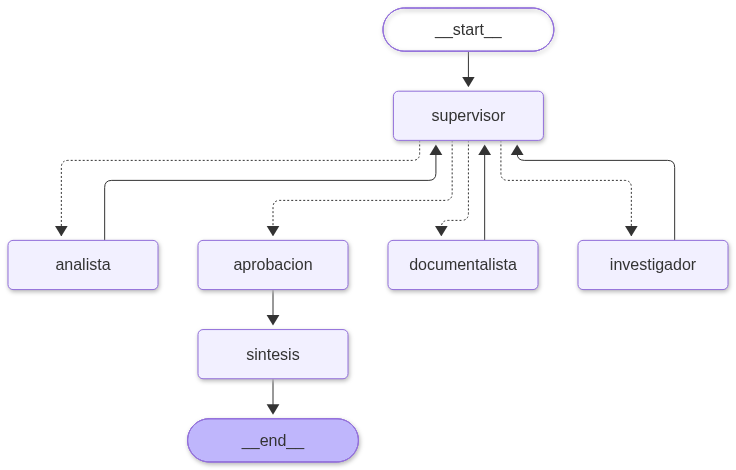

In [48]:
import importlib
import os

import app.graph
importlib.reload(app.graph)
from IPython.display import Image, display

from app.graph import construir_grafo

os.makedirs("docs", exist_ok=True)
grafo_dibujo = construir_grafo(None).get_graph()
print(grafo_dibujo.draw_mermaid())
try:
    png = grafo_dibujo.draw_mermaid_png()
    open("docs/grafo.png", "wb").write(png)
    display(Image(png))
except Exception as e:
    print("No se pudo generar el PNG:", type(e).__name__)

## 33. Archivos de despliegue

In [49]:
%%writefile requirements.txt
fastapi
uvicorn[standard]
httpx
redis
pydantic
python-dotenv
langgraph
langgraph-checkpoint-redis
langchain-core
langchain-community
langchain-classic
langchain-google-genai
langchain-chroma
langchain-huggingface
langchain-text-splitters
chromadb
sentence-transformers
rank_bm25
tiktoken
arize-phoenix-otel
openinference-instrumentation-langchain
pytest
pytest-asyncio

Writing requirements.txt


In [50]:
%%writefile .env.example
# Clave de Gemini (gratis en aistudio.google.com)
GOOGLE_API_KEY=tu_clave_de_gemini

# Infraestructura (con Docker Compose se reemplazan solas)
REDIS_URL=redis://localhost:6379
PHOENIX_COLLECTOR_ENDPOINT=http://localhost:6006/v1/traces
PHOENIX_PROJECT_NAME=intelligence-system

# Modelos: el primero es el principal y los demás son respaldos
MODELOS_SUPERVISOR=gemini-3.5-flash-lite,gemini-3.1-flash-lite,gemini-flash-lite-latest
MODELOS_ESPECIALISTAS=gemini-3.5-flash,gemini-3.6-flash,gemini-3.5-flash-lite,gemini-3.1-flash-lite
LLM_TIMEOUT=60

# RAG
EMBEDDINGS_MODEL=intfloat/multilingual-e5-small
CONOCIMIENTO_DIR=conocimiento
CHROMA_DIR=vectorstore
CHROMA_COLLECTION=conocimiento_tienda
RAG_TOP_K=4
RAG_CHUNK_SIZE=500
RAG_CHUNK_OVERLAP=50
RAG_PESO_BM25=0.5

# Agentes y API
MAX_PASOS_SUPERVISOR=8
RECURSION_LIMIT_ESPECIALISTA=10
RECURSION_LIMIT_GRAFO=30
MAX_MENSAJES_HISTORIAL=10
PAUSA_ENTRE_NODOS=4
WORKERS=2
JOB_TTL_SEGUNDOS=86400

Writing .env.example


In [51]:
%%writefile .gitignore
.env
.venv/
__pycache__/
*.pyc
*.log
vectorstore/
.pytest_cache/

Writing .gitignore


In [52]:
%%writefile Dockerfile
FROM python:3.12-slim
WORKDIR /code

# PyTorch en versión CPU (mucho más liviana) para el modelo de embeddings
RUN pip install --no-cache-dir torch --index-url https://download.pytorch.org/whl/cpu
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY app ./app
COPY conocimiento ./conocimiento
COPY tests ./tests
COPY pytest.ini .

EXPOSE 8000
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]

Writing Dockerfile


In [53]:
%%writefile docker-compose.yml
services:
  redis:
    image: redis:8                  # incluye los módulos JSON y Search que usa el checkpointer
    ports:
      - "6379:6379"
    volumes:
      - redis-data:/data            # trabajos, reservas y conversaciones sobreviven a un reinicio

  phoenix:
    image: arizephoenix/phoenix:latest
    ports:
      - "6006:6006"
    volumes:
      - phoenix-data:/root/.phoenix

  api:
    build: .
    env_file: .env
    environment:
      REDIS_URL: redis://redis:6379
      PHOENIX_COLLECTOR_ENDPOINT: http://phoenix:6006/v1/traces
      CHROMA_DIR: /data/vectorstore
    ports:
      - "8000:8000"
    volumes:
      - chroma-data:/data           # base vectorial (la ingesta se hace una sola vez)
      - hf-cache:/root/.cache/huggingface
    depends_on:
      - redis
      - phoenix

volumes:
  redis-data:
  phoenix-data:
  chroma-data:
  hf-cache:

Writing docker-compose.yml


In [54]:
%%writefile run.sh
#!/usr/bin/env bash
# Levanta todo el sistema (Redis + Phoenix + API) con una sola instrucción: bash run.sh
set -e

if [ ! -f .env ]; then
  cp .env.example .env
  echo "Se creó el archivo .env: completá GOOGLE_API_KEY y volvé a ejecutar 'bash run.sh'."
  exit 1
fi

docker compose up --build -d

echo "Esperando a que la API esté lista (la primera vez descarga el modelo de embeddings)..."
for i in $(seq 1 60); do
  if curl -fs http://localhost:8000/health > /dev/null; then
    echo ""
    echo "Sistema listo:"
    echo "  API y documentación: http://localhost:8000/docs"
    echo "  Phoenix (trazas):    http://localhost:6006"
    echo "  Demo de 5 pruebas:   python scripts/demo.py"
    exit 0
  fi
  sleep 5
done
echo "La API no respondió. Revisá los logs con: docker compose logs api"
exit 1

Writing run.sh


## 34. Script de demostración (las 5 pruebas, para repetirlas fuera de Colab)

In [55]:
%%writefile scripts/demo.py
"""Ejecuta las 5 pruebas del sistema contra la API. Uso: python scripts/demo.py [url]"""
import asyncio
import sys

import httpx

API = sys.argv[1] if len(sys.argv) > 1 else "http://localhost:8000"
FINALES = {"DONE", "FAILED", "WAITING_APPROVAL"}


async def esperar(cliente: httpx.AsyncClient, job_id: str) -> dict:
    while True:
        try:
            trabajo = (await cliente.get(f"{API}/tasks/{job_id}")).json()
            if trabajo["estado"] in FINALES:
                return trabajo
        except httpx.TransportError:
            pass
        await asyncio.sleep(3)


async def prueba(cliente: httpx.AsyncClient, titulo: str, consulta: str, thread_id: str | None = None) -> dict:
    print(f"\n=== {titulo} ===\nConsulta: {consulta}")
    r = await cliente.post(f"{API}/tasks", json={"consulta": consulta, "thread_id": thread_id})
    trabajo = await esperar(cliente, r.json()["job_id"])
    resultado = trabajo.get("resultado") or {}
    print(f"Estado: {trabajo['estado']} | Flujo: {' -> '.join(resultado.get('flujo', []))}")
    print("Respuesta:", resultado.get("respuesta_final") or trabajo.get("error") or trabajo.get("aprobacion_pendiente"))
    return trabajo


async def main() -> None:
    async with httpx.AsyncClient(timeout=30) as c:
        await prueba(c, "1. RAG", "¿Cuántos días tengo para devolver un producto y quién paga el envío de la devolución?")
        await prueba(c, "2. Multi-agente", "Compará los Pulse X1 y los Nova Pro: puntaje promedio de los clientes, "
                     "cuál conviene más por precio/calidad y cuánta garantía tiene cada uno.", "demo")
        await prueba(c, "3. Memoria", "¿Y si no me gustan, los puedo devolver aunque los haya abierto?", "demo")
        t4 = await prueba(c, "4. HITL", "Perfecto, reservame el que convenía más.", "demo")
        if t4["estado"] == "WAITING_APPROVAL":
            await c.post(f"{API}/tasks/{t4['id']}/approve", json={"aprobado": True, "operador": "demo"})
            final = await esperar(c, t4["id"])
            print("Después de aprobar:", final["estado"], "|", (final.get("resultado") or {}).get("accion_ejecutada"))
        await prueba(c, "5. Anti-alucinación", "¿Hacen envíos a Uruguay? ¿Cuánto cuestan?")


if __name__ == "__main__":
    asyncio.run(main())

Writing scripts/demo.py


## 35. README

In [56]:
%%writefile README.md
# Sistema Intelligence: asistente multi-agente con RAG

Asistente para una tienda de tecnología que responde consultas complejas combinando cuatro piezas:
conocimiento específico (RAG sobre las políticas de la tienda), razonamiento multi-paso (un Supervisor
que coordina a tres agentes especialistas), una API REST profesional y documentada (FastAPI con
validación Pydantic) y trazabilidad completa (Arize Phoenix).

Ejemplo de consulta que resuelve: "Compará los Pulse X1 y los Nova Pro, decime cuál conviene y cuánta
garantía tiene cada uno". Después, en la misma conversación: "¿Y si no me gustan, los puedo devolver?".


## Levantar el sistema (una sola instrucción)

Requisitos: Docker con Docker Compose.

```
bash run.sh
```

La primera vez crea el archivo .env a partir de .env.example: completar GOOGLE_API_KEY (gratis en
aistudio.google.com) y volver a ejecutar. El script levanta Redis, Phoenix y la API, y espera a que
estén listos.

- API y documentación interactiva (Swagger): http://localhost:8000/docs
- Phoenix (trazas): http://localhost:6006

Equivalente manual: docker compose up --build


## Arquitectura

```mermaid
flowchart LR
    C[Cliente] -->|POST /tasks| API[API FastAPI]
    API -->|guarda PENDING| R[(Redis)]
    API -->|encola| Q[Cola asyncio]
    Q --> W[Workers]
    W --> G[Grafo de agentes LangGraph]
    G <-->|checkpoints por thread_id| R
    G -->|búsqueda híbrida| V[(ChromaDB + BM25)]
    G -->|LLM| GEM[Gemini]
    W -->|trazas| P[Arize Phoenix]
    H[Operador humano] -->|POST /tasks/id/approve| API
```

1. POST /tasks valida la consulta con Pydantic, guarda el trabajo en Redis como PENDING, lo encola y
   responde enseguida (202) con un job_id y un thread_id. La API nunca espera al agente.
2. Un worker toma el trabajo y ejecuta el grafo. El checkpointer guarda el estado de la conversación
   en Redis en cada paso.
3. Si la consulta pide una acción crítica (reservar, apartar, pagar), el grafo se pausa con
   interrupt() y el trabajo queda en WAITING_APPROVAL hasta que un humano responde.
4. El trabajo termina en DONE con su resultado, o en FAILED con el error. El cliente consulta
   GET /tasks/{job_id}.


## Grafo de agentes

```mermaid
flowchart TD
    START([inicio]) --> SUP[Supervisor<br/>decide y valida con una rúbrica]
    SUP -.->|delega| INV[Investigador<br/>catálogo y reseñas]
    SUP -.->|delega| ANA[Analista<br/>estadísticas, sentimiento y cálculos]
    SUP -.->|delega| DOC[Documentalista<br/>RAG sobre políticas]
    INV --> SUP
    ANA --> SUP
    DOC --> SUP
    SUP -.->|FINALIZAR| APR{Aprobación humana<br/>solo si la acción es crítica}
    APR --> SIN[Síntesis<br/>respuesta final]
    SIN --> FIN([fin])
```

Diagrama generado por LangGraph: docs/grafo.png. Las líneas punteadas son la arista condicional del
supervisor (retorno Literal con el nombre del nodo); cada especialista vuelve siempre al supervisor.

| Agente | Herramientas | Límite de su rol |
| --- | --- | --- |
| Supervisor | Salida estructurada (DecisionSupervisor) | No busca ni calcula; solo delega y valida |
| Investigador | buscar_productos, obtener_resenas | No calcula ni consulta políticas |
| Analista | calcular_estadisticas, analizar_sentimiento, calcular | No busca información |
| Documentalista | buscar_conocimiento (RAG) | Solo responde con lo que está en los documentos |
| Síntesis | Ninguna | No agrega datos nuevos |


## Estructura del proyecto

```
app/
  main.py            API FastAPI (todos los endpoints con modelos Pydantic de entrada y salida)
  worker.py          cola de trabajos y estado en Redis
  graph.py           grafo de agentes + checkpointer
  hitl.py            aprobación humana con interrupt()
  observability.py   Arize Phoenix con OpenInference
  schemas.py         contratos Pydantic de la API y de las herramientas
  config.py          configuración desde variables de entorno, validada con Pydantic
  state.py           estado compartido del grafo
  datos.py           catálogo simulado
  agents/            supervisor, investigador, analista, documentalista
  rag/               ingesta (fragmentación por secciones) y recuperador híbrido
conocimiento/        políticas de la tienda en Markdown (base del RAG)
tests/               tests automáticos (pytest)
scripts/demo.py      las 5 pruebas del sistema contra la API
docs/grafo.png       diagrama del grafo
screenshots/         capturas de Phoenix
Pre_trabajo_final.ipynb  notebook de Colab donde se desarrolló y probó todo
```


## Endpoints

| Método y ruta | Qué hace |
| --- | --- |
| POST /tasks | Envía una consulta. Con thread_id continúa una conversación; sin él, crea una nueva |
| GET /tasks/{job_id} | Estado del trabajo y su resultado (respuesta, flujo de agentes, fuentes) |
| POST /tasks/{job_id}/approve | Aprueba o rechaza una acción crítica pausada |
| GET /conversations/{thread_id} | Historial de una conversación, leído del checkpointer |
| GET /reservas | Reservas registradas por la acción crítica |
| GET /health | Estado de la API, Redis y la base de conocimiento |


## Cómo cumple los requisitos

| Requisito | Implementación |
| --- | --- |
| Integración de los módulos 6 y 7 | Orquestador multi-agente (M6) dentro de la API con Redis y Phoenix (M7), en una sola estructura |
| Todo asíncrono | Endpoints async, Redis con redis.asyncio, grafo y LLM con ainvoke, Chroma con sus métodos async; lo pesado y sincrónico (cargar el modelo de embeddings) corre con asyncio.to_thread |
| Checkpointer | AsyncRedisSaver con thread_id por conversación: el historial sobrevive a un reinicio del servidor (prueba 3) |
| Validación con Pydantic | schemas.py: entradas y salidas de todos los endpoints (response_model), de todas las herramientas (args_schema y objetos de salida), la decisión del supervisor y la configuración |
| Observabilidad | Una traza por trabajo en Phoenix, con session.id = thread_id para agrupar conversaciones y status ERROR en las fallas |
| Sin hard-coding | Modelos, colección de Chroma, URLs y límites salen del .env |
| Despliegue local | bash run.sh o docker compose up |


## Pruebas

Tests automáticos (sin LLM): 16 tests de esquemas, herramientas y validaciones.

```
pytest
```

Pruebas del sistema (con trazas en Phoenix), repetibles con python scripts/demo.py:

| N° | Consulta | Flujo | Resultado |
| --- | --- | --- | --- |
| 1 | ¿Cuántos días tengo para devolver y quién paga el envío? | supervisor, documentalista, supervisor, síntesis | 10 días corridos; envío gratis por arrepentimiento (fuente: devoluciones.md) |
| 2 | Compará Pulse X1 y Nova Pro: puntaje, precio/calidad y garantía | supervisor, investigador, supervisor, analista, supervisor, síntesis | 4,2 contra 3,8; conviene el Pulse X1 ($10.714 contra $16.316 por punto); garantía 12 y 18 meses |
| 3 | (después de reiniciar la API) ¿Y si no me gustan, los puedo devolver aunque los haya abierto? | supervisor, documentalista, supervisor, síntesis | Recuperó el historial de Redis y entendió que "los" eran el Pulse X1 y el Nova Pro: sí, si están sin uso |
| 4 | Perfecto, reservame el que convenía más | WAITING_APPROVAL, aprobación, síntesis | Reserva N° 1 del Pulse X1, aprobada por un operador |
| 5 | ¿Hacen envíos a Uruguay? | supervisor, documentalista, supervisor, síntesis | "No se encuentra en las políticas de la tienda": no inventó la respuesta |
| Extra | Falla forzada | | Estado FAILED con el error, sin dejar al cliente esperando |


## Observabilidad (carpeta screenshots/)

- 01_trazas.png: una traza por trabajo.
- 02_traza_multiagente.png: árbol de la prueba 2, con el supervisor y los especialistas.
- 03_traza_rag.png: la búsqueda en la base de conocimiento y los fragmentos recuperados.
- 04_sesion.png: las 3 preguntas de la conversación demo-final agrupadas como sesión.
- 05_traza_hitl.png: ejecución pausada en el nodo aprobacion.
- 06_traza_fallida.png: el trabajo con falla forzada, marcado como error.


## Decisiones de diseño

- RAG con ChromaDB local (en lugar de Pinecone) para que el sistema se levante con un solo comando y sin
  cuentas externas. Fragmentación por secciones del Markdown, con metadatos de fuente, categoría,
  título y sección. Búsqueda híbrida BM25 + vectorial (pesos 0,5 / 0,5), top_k = 4.
- Contexto acotado: cada especialista recibe solo su instrucción (y el analista, los datos del
  investigador), no toda la conversación. El supervisor y la síntesis reciben el historial resumido
  (preguntas y respuestas finales).
- Condiciones de parada: máximo de pasos del supervisor, recursion_limit en el grafo y en cada
  especialista.
- Resiliencia: cada agente tiene una lista de modelos de Gemini; si uno falla o supera el tiempo
  máximo, se usa el siguiente.
- Gemini por su plan gratuito: tiene cupos bajos por día y por minuto, por eso hay pausas entre nodos
  y 2 workers.


## Limitaciones conocidas

- En la prueba 2, la síntesis escribió que el Pulse X1 es "un 37,78% más económico". El analista calculó
  bien que el Nova Pro es 37,78% más caro, pero el ahorro real del Pulse X1 es del 27,4%. La rúbrica del
  supervisor valida a los especialistas, no a la síntesis. Mejora propuesta: un nodo final que verifique
  los números de la respuesta contra las contribuciones.
- El detector de acciones críticas usa palabras clave; un clasificador con el LLM sería más flexible.
- La reserva registra la solicitud, no el producto: el producto elegido queda en la respuesta.

Writing README.md


## 36. Descargar el proyecto

In [57]:
!rm -rf app/__pycache__ app/agents/__pycache__ app/rag/__pycache__ tests/__pycache__ .pytest_cache
!zip -r trabajo-final.zip app conocimiento tests scripts docs pytest.ini requirements.txt .env.example .gitignore Dockerfile docker-compose.yml run.sh README.md

from google.colab import files
files.download("trabajo-final.zip")

  adding: app/ (stored 0%)
  adding: app/observability.py (deflated 49%)
  adding: app/hitl.py (deflated 57%)
  adding: app/datos.py (deflated 57%)
  adding: app/__init__.py (deflated 8%)
  adding: app/main.py (deflated 64%)
  adding: app/worker.py (deflated 66%)
  adding: app/config.py (deflated 59%)
  adding: app/graph.py (deflated 66%)
  adding: app/rag/ (stored 0%)
  adding: app/rag/__init__.py (deflated 3%)
  adding: app/rag/retriever.py (deflated 61%)
  adding: app/rag/ingest.py (deflated 61%)
  adding: app/agents/ (stored 0%)
  adding: app/agents/__init__.py (deflated 9%)
  adding: app/agents/supervisor.py (deflated 62%)
  adding: app/agents/analyst_agent.py (deflated 59%)
  adding: app/agents/research_agent.py (deflated 59%)
  adding: app/agents/knowledge_agent.py (deflated 56%)
  adding: app/agents/base.py (deflated 60%)
  adding: app/state.py (deflated 57%)
  adding: app/schemas.py (deflated 70%)
  adding: conocimiento/ (stored 0%)
  adding: conocimiento/envios.md (deflated 4

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>